# TEMA: INVERSIÓN EN ECONOMÍAS VERDES

## Equipo: FULL STORM
## Integrantes: 
### Larico Almaraz Paola Andrea
### Tucuman Alarcón Paola Andrea

In [1]:
#Importacion de librerias

import refinitiv.data as rd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

rd.open_session()

An error occurred while requesting URL('http://localhost:9000/api/status').
	ConnectError('[WinError 10061] No connection could be made because the target machine actively refused it')
An error occurred while requesting URL('http://localhost:9000/api/status').
	ConnectError('[WinError 10061] No connection could be made because the target machine actively refused it')
An error occurred while requesting URL('http://localhost:9060/api/status').
	ConnectError('[WinError 10061] No connection could be made because the target machine actively refused it')
Error: no proxy address identified.
Check if Desktop is running.
An error occurred while requesting URL('http://localhost:9000/api/handshake').
	ConnectError('[WinError 10061] No connection could be made because the target machine actively refused it')
Error on handshake url http://localhost:9000/api/handshake : ConnectError('[WinError 10061] No connection could be made because the target machine actively refused it')


<refinitiv.data.session.Definition object at 0x1ea0cfd44d0 {name='workspace'}>

### RECOLECCION DE DATOS ESG

Ventajas generales de extraer variables individuales en lugar del Score ESG:

## Granularidad y especificidad: 
Los ESG Scores son promedios ponderados de múltiples factores, lo que puede ocultar fortalezas o debilidades específicas de una empresa. Al extraer variables individuales, se puede realizar un análisis más preciso y segmentado sobre aspectos particulares del desempeño de la empresa, como su inversión en energía renovable o su compromiso con la diversidad en la junta.

## Comparabilidad directa: 
Comparabilidad directa entre empresas: Algunas empresas pueden obtener un ESG Score alto debido a su desempeño en un área específica (por ejemplo, gobernanza) pero tener deficiencias en otras áreas (como el impacto ambiental). Al observar las variables de forma individual, se puede comparar a las empresas en función de criterios específicos que sean más relevantes para el análisis, como el uso de energía renovable o las políticas de diversidad.

In [3]:
#Recoleccion de datos de 3 Indices: SP500, NASDAQ y DOWN JONES
ric_list_2 = ['0#.SPX','0#.NDX','0#.DJI']
fields_2 = ['TR.GICSSector',
            'TR.CO2EmissionTotal(Frq=FY, Period=FY2022)',
            'TR.TotalRenewableEnergy(Frq=FY, Period=FY2022)',
            'TR.WaterWithdrawalTotal(Frq=FY, Period=FY2022)',
            'TR.WasteTotal(Frq=FY, Period=FY2022)',
            'TR.EnergyUseTotal(Frq=FY, Period=FY2022)',
            'TR.DonationsTotal(Frq=FY, Period=FY2022)',
            'TR.PolicyDiversityOpportunity(Frq=FY, Period=FY2022)',
            'TR.PolicyBoardDiversity(Frq=FY, Period=FY2022)']

data_esg = rd.get_data(ric_list_2,fields_2)
data_esg.head(15)
data_esg.shape

(634, 10)

# VARIABLES QUE FORMAN PARTE DEL MODELO

## GICSetor: 
Sector al que pertenece la empresa.

## Emisiones Totales de CO2 (CO2 Equivalent Emission Total):
Las emisiones de carbono son un indicador directo del impacto ambiental de una empresa, medidos en toneladas. Reducir las emisiones de carbono es una de las prioridades más importantes para muchas industrias en la transición hacia una economía verde.

## Energía Total Renovable (Total Renewable Energy):
Esta variable mide la cantidad total de energía que una empresa obtiene a partir de fuentes de energía renovable, como solar, eólica, geotérmica, biomasa, e hidroeléctrica. Medido en gigajuoles. Es un indicador clave del compromiso de una empresa con la sostenibilidad ambiental y la reducción de su huella de carbono.

## Uso total de agua (Wate Withdrawal Total):  
Esta variable mide el consumo total de agua de una empresa en metros cÚbicos. Es importante desde una perspectiva ambiental, ya que el uso excesivo de recursos hídricos puede afectar la sostenibilidad a largo plazo, especialmente en áreas con escasez de agua.

## Residuos generados (Waste Total): 
El volumen de residuos generados es un indicador del impacto ambiental de una empresa, reflejando su eficiencia en la gestión de recursos y sus esfuerzos para minimizar el desperdicio. Medido en toneladas.

## Uso total de energía (Energy Use Total): 
Esta variable mide el consumo de energía de una empresa medido en gigajoules, lo que está directamente relacionado con su huella de carbono y sus esfuerzos para reducir las emisiones de gases de efecto invernadero.

## Total de Donaciones (Donatios Total): 
Esta variable mide el monto total de donaciones realizadas por la empresa durante el año fiscal 2022. Las donaciones pueden incluir contribuciones a organizaciones benéficas, fundaciones u otros programas de impacto social.

## Política de Diversidad y Oportunidades (Policy Diversity and Opportunity):
Esta variable mide si la empresa tiene políticas formales que promueven la diversidad y la igualdad de oportunidades en el lugar de trabajo. Esto puede incluir políticas contra la discriminación, igualdad de acceso a oportunidades de empleo y formación sobre diversidad e inclusión.

## Política de Diversidad en la Junta Directiva (Policy Board Diversity):
Esta variable indica si la empresa tiene una política específica que fomente la diversidad dentro de su junta directiva. La diversidad en la junta directiva puede abarcar aspectos como género, etnia, experiencia y habilidades.




In [4]:
#Eliminar datos duplicados 
data_esg= data_esg.drop_duplicates(subset=['Instrument'])
data_esg.head(10)

,Instrument,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
0,POOL.OQ,Consumer Discretionary,58800.0,<NA>,<NA>,<NA>,633147.0656,2000000,True,True
1,CHRW.OQ,Industrials,27722.0,62514.0,<NA>,<NA>,302112.0,4038946,True,True
2,AJG.N,Financials,34625.0,<NA>,<NA>,<NA>,<NA>,<NA>,True,True
3,CNP.N,Utilities,4891379.0,434235.6,180438733.0,82897.0,<NA>,14800000,True,True
4,AMCR.N,Materials,1883381.0,314538.0,6993348.0,412168.0,19995862.0,<NA>,True,True
5,WM.N,Industrials,15623620.0,7306851.6,3370000.0,4561.0,32538517.2,15900000,True,True
6,BA.N,Industrials,1421000.0,2624400.0,4603000.0,80090.0,18118800.0,<NA>,True,True
7,FOX.OQ,Communication Services,66378.0,6181.2,44675.0,<NA>,827316.0,<NA>,True,True
8,WY.N,Real Estate,900000.0,26417647.34,2492000.0,5038243.1385,36182227.64,5600000,True,True
9,MCD.N,Consumer Discretionary,338175.0,<NA>,1793462.0,<NA>,<NA>,<NA>,True,True


In [5]:
# Reemplazar NA de las variables ambientales con la mediana del sector

data_esg['CO2 Equivalent Emissions Total'] = data_esg.groupby('GICS Sector Name')['CO2 Equivalent Emissions Total'].transform(lambda x: x.fillna(x.median()))
data_esg['Total Renewable Energy'] = data_esg.groupby('GICS Sector Name')['Total Renewable Energy'].transform(lambda x: x.fillna(x.median()))
data_esg['Water Withdrawal Total'] = data_esg.groupby('GICS Sector Name')['Water Withdrawal Total'].transform(lambda x: x.fillna(x.median()))
data_esg['Waste Total'] = data_esg.groupby('GICS Sector Name')['Waste Total'].transform(lambda x: x.fillna(x.median()))
data_esg['Energy Use Total'] = data_esg.groupby('GICS Sector Name')['Energy Use Total'].transform(lambda x: x.fillna(x.median()))


# Reemplazar NA en las variables de políticas inclusivas y donaciones con 0 (asume que no tienen estas politicas)
data_esg['Donations Total'] = data_esg['Donations Total'].fillna(0)
data_esg['Policy Diversity and Opportunity'] = data_esg['Policy Diversity and Opportunity'].fillna(False)
data_esg['Policy Board Diversity'] = data_esg['Policy Board Diversity'].fillna(False)

data_esg.head(15)


,Instrument,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
0,POOL.OQ,Consumer Discretionary,58800.0,447301.0,5865575.0,129273.5,633147.0656,2000000,True,True
1,CHRW.OQ,Industrials,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,True,True
2,AJG.N,Financials,34625.0,119407.32,229100.0,1455.996105,600397.2,0,True,True
3,CNP.N,Utilities,4891379.0,434235.6,180438733.0,82897.0,65774943.0,14800000,True,True
4,AMCR.N,Materials,1883381.0,314538.0,6993348.0,412168.0,19995862.0,0,True,True
5,WM.N,Industrials,15623620.0,7306851.6,3370000.0,4561.0,32538517.2,15900000,True,True
6,BA.N,Industrials,1421000.0,2624400.0,4603000.0,80090.0,18118800.0,0,True,True
7,FOX.OQ,Communication Services,66378.0,6181.2,44675.0,57651.1,827316.0,0,True,True
8,WY.N,Real Estate,900000.0,26417647.34,2492000.0,5038243.1385,36182227.64,5600000,True,True
9,MCD.N,Consumer Discretionary,338175.0,447301.0,1793462.0,129273.5,5184000.0,0,True,True


In [6]:
df_esg = pd.DataFrame(data_esg)
df_esg.info()
df_esg.shape

<class 'pandas.core.frame.DataFrame'>
Int64Index: 519 entries, 0 to 578
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Instrument                        519 non-null    string 
 1   GICS Sector Name                  519 non-null    string 
 2   CO2 Equivalent Emissions Total    519 non-null    Float64
 3   Total Renewable Energy            519 non-null    Float64
 4   Water Withdrawal Total            519 non-null    Float64
 5   Waste Total                       519 non-null    Float64
 6   Energy Use Total                  519 non-null    Float64
 7   Donations Total                   519 non-null    Int64  
 8   Policy Diversity and Opportunity  519 non-null    boolean
 9   Policy Board Diversity            519 non-null    boolean
dtypes: Float64(5), Int64(1), boolean(2), string(2)
memory usage: 41.6 KB


(519, 10)

In [7]:
#Transformar las variables 'GICS Sector Name' e 'Instrument' al formato object para análisis posteriores

df_esg['GICS Sector Name'] = data_esg['GICS Sector Name'].astype('object')
df_esg['Instrument'] = data_esg['Instrument'].astype('object')
df_esg.head(10)

,Instrument,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
0,POOL.OQ,Consumer Discretionary,58800.0,447301.0,5865575.0,129273.5,633147.0656,2000000,True,True
1,CHRW.OQ,Industrials,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,True,True
2,AJG.N,Financials,34625.0,119407.32,229100.0,1455.996105,600397.2,0,True,True
3,CNP.N,Utilities,4891379.0,434235.6,180438733.0,82897.0,65774943.0,14800000,True,True
4,AMCR.N,Materials,1883381.0,314538.0,6993348.0,412168.0,19995862.0,0,True,True
5,WM.N,Industrials,15623620.0,7306851.6,3370000.0,4561.0,32538517.2,15900000,True,True
6,BA.N,Industrials,1421000.0,2624400.0,4603000.0,80090.0,18118800.0,0,True,True
7,FOX.OQ,Communication Services,66378.0,6181.2,44675.0,57651.1,827316.0,0,True,True
8,WY.N,Real Estate,900000.0,26417647.34,2492000.0,5038243.1385,36182227.64,5600000,True,True
9,MCD.N,Consumer Discretionary,338175.0,447301.0,1793462.0,129273.5,5184000.0,0,True,True


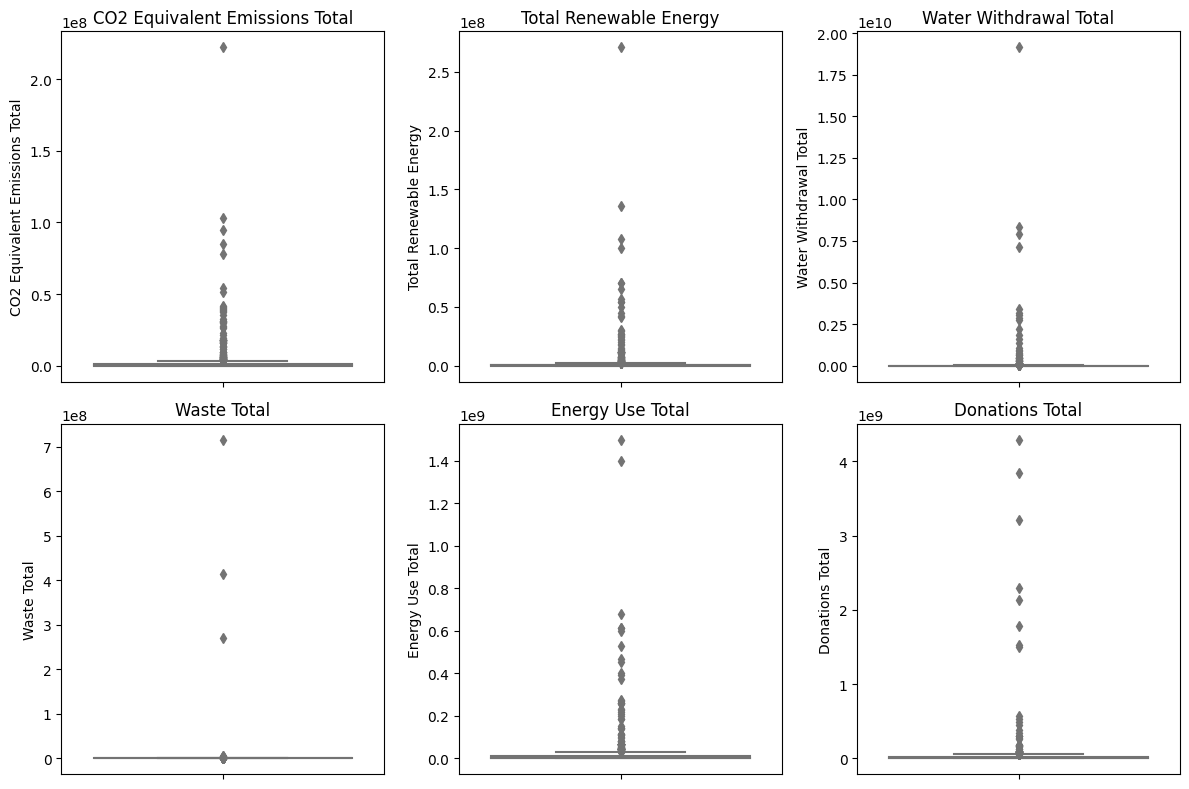

In [8]:
#GRÁFICOS DE CAJAS ANTES DE LA ELIMINACIÓN DE OUTLINERS

# Crear una figura y ajustar su tamaño
plt.figure(figsize=(12, 8))

# Definir las columnas numéricas que deseas graficar
columnas_numericas = [
    'CO2 Equivalent Emissions Total', 
    'Total Renewable Energy', 
    'Water Withdrawal Total', 
    'Waste Total', 
    'Energy Use Total', 
    'Donations Total'
]

# Graficar boxplots para cada una de las columnas numéricas
for i, columna in enumerate(columnas_numericas):
    plt.subplot(2, 3, i+1)  # Crear un subplot
    sns.boxplot(y=df_esg[columna], palette ='rainbow')
    plt.title(f'{columna}')
    plt.tight_layout()
plt.show()


In [9]:
#Eliminar valores extermos u outliers

# Definir las columnas numéricas donde deseas eliminar outliers
columnas_numericas = [
    'CO2 Equivalent Emissions Total', 
    'Total Renewable Energy', 
    'Water Withdrawal Total', 
    'Waste Total', 
    'Energy Use Total', 
    'Donations Total']

# Definir una función para eliminar outliers usando IQR
def eliminar_outliers_iqr(df_esg, columnas):
    for columna in columnas:
# Calcular Q1 (percentil 25) y Q3 (percentil 75)
        Q1 = df_esg[columna].quantile(0.25)
        Q3 = df_esg[columna].quantile(0.75)
        IQR = Q3 - Q1  # Rango intercuartílico
        
        # Definir los límites inferior y superior
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR
        
        # Eliminar las filas donde los valores estén fuera de los límites
        df_esg = df_esg[(df_esg[columna] >= limite_inferior) & 
                    (df_esg[columna] <= limite_superior)]

    return df_esg

# Aplicar la función al DataFrame
df_esg = eliminar_outliers_iqr(df_esg, columnas_numericas)

# Mostrar el DataFrame sin outliers
print(df_esg)
df_esg.shape

    Instrument        GICS Sector Name  CO2 Equivalent Emissions Total  \
1      CHRW.OQ             Industrials                         27722.0   
2        AJG.N              Financials                         34625.0   
7       FOX.OQ  Communication Services                         66378.0   
12     HBAN.OQ              Financials                         72240.0   
13     QRVO.OQ  Information Technology                        281550.0   
..         ...                     ...                             ...   
552    ILMN.OQ             Health Care                         39924.0   
561     GFS.OQ  Information Technology                        108737.5   
570    DDOG.OQ  Information Technology                          1814.0   
574      ZS.OQ  Information Technology                         23154.0   
578    ASML.OQ  Information Technology                        210200.0   

     Total Renewable Energy  Water Withdrawal Total  Waste Total  \
1                   62514.0              12

(238, 10)

### GRÁFICOS DE DATOS ESG - ANÁLISIS EDA

In [10]:
# Eliminar las variables relacionadas con las políticas, ya que al ser binarias no es posible calcular la media y no aportan información útil para los análisis posteriores.
df_esg_no_policy = df_esg.drop(columns=['Policy Diversity and Opportunity','Policy Board Diversity'])


In [11]:
# Agrupación de datos por sector y cálculo de la media de las variables ambientales
df_group_sector = df_esg_no_policy.groupby('GICS Sector Name').mean()
df_group_sector

,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total
GICS Sector Name,,,,,,
Communication Services,122084.336364,104665.960364,4534062.654545,57651.1,899198.4,3054545.454545
Consumer Discretionary,220659.389625,283136.00875,2968930.109494,32178.7225,2060820.3115,8681989.125
Consumer Staples,279311.0,575433.2448,3718763.5014,73442.0,3889266.5,15250000.0
Financials,47575.165302,110000.106506,282830.614802,1790.494832,586957.176351,5951014.867925
Health Care,145096.382195,305059.237161,1361814.592225,20310.311293,2313169.655847,4314268.804878
Industrials,208048.962432,232089.212404,1013862.8877,40352.141531,2008497.717975,3128647.590909
Information Technology,134174.370893,290400.452916,1424807.633978,6846.877367,1016673.10708,2793119.214286
Materials,155000.0,272000.0,1300000.0,73485.0,2474000.0,75000.0
Real Estate,171643.727273,181596.813236,4427239.473979,45913.852349,1313199.725782,1627222.318182


Text(0.5, 1.0, 'Promedio de las variables del ESG por Sector')

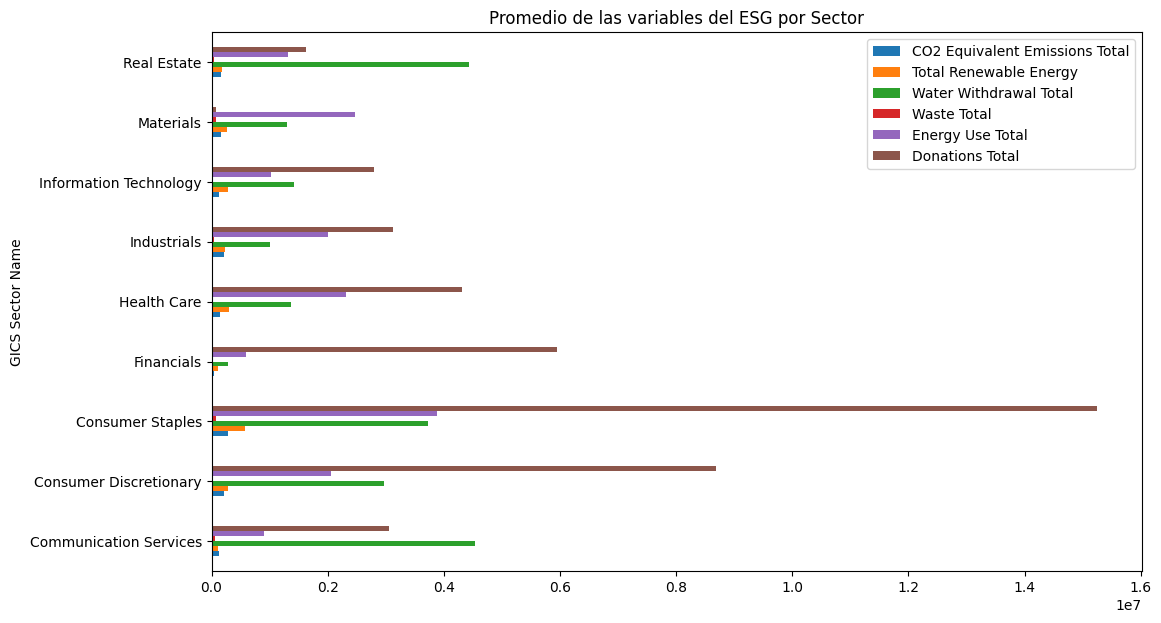

In [12]:
ax = df_group_sector.plot.barh(rot=0,figsize=(12,7))
plt.title('Promedio de las variables del ESG por Sector')

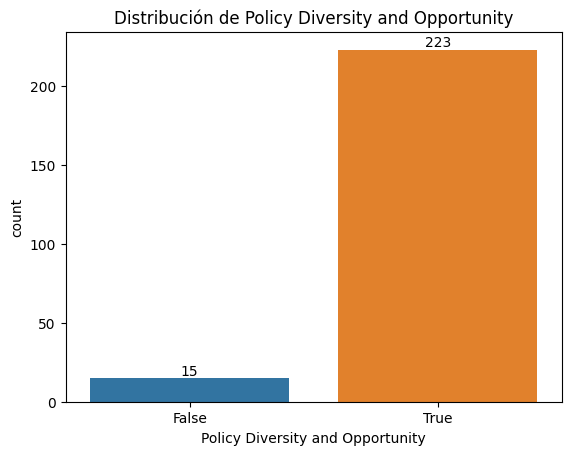

In [13]:
#Gráfico de la distribución de la variable Policy Diversity and Opportunity
ax = sns.countplot(data=df_esg, x='Policy Diversity and Opportunity')

plt.title('Distribución de Policy Diversity and Opportunity')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom')  
plt.show()

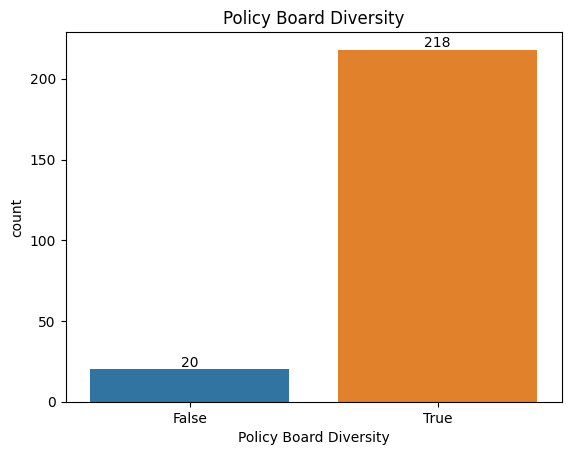

In [14]:
#Gráfico de la distribución de la variable Policy Board Diversity
ax = sns.countplot(data=df_esg, x='Policy Board Diversity')

plt.title('Policy Board Diversity')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom')  
plt.show()

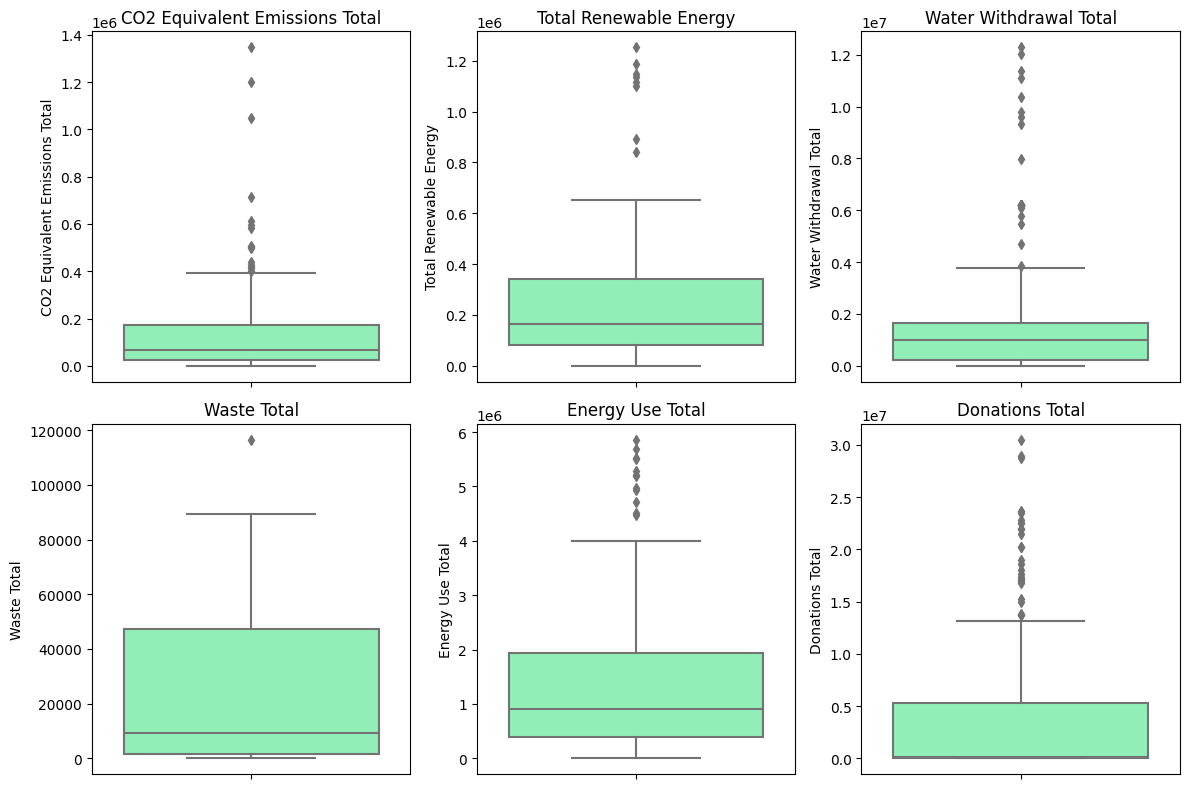

In [15]:
#GRÁFICOS DE CAJAS PARA VERIFICAR LA AUSENCIA DE OUTLINERS O VALORES EXTREMOS

# Crear una figura y ajustar su tamaño
plt.figure(figsize=(12, 8))

# Definir las columnas numéricas que deseas graficar
columnas_numericas = [
    'CO2 Equivalent Emissions Total', 
    'Total Renewable Energy', 
    'Water Withdrawal Total', 
    'Waste Total', 
    'Energy Use Total', 
    'Donations Total'
]

# Graficar boxplots para cada una de las columnas numéricas
for i, columna in enumerate(columnas_numericas):
    plt.subplot(2, 3, i+1)  # Crear un subplot
    sns.boxplot(y=df_esg[columna], palette ='rainbow')
    plt.title(f'{columna}')
    plt.tight_layout()
plt.show()



# MODELO DE CLASIFICACIÓN DE MACHINE LEARNING (CLUSTERING) PARA SELECCIÓN DE EMPRESAS A INVERTIR

In [16]:
# Crear una copia de la base de datos para evitar cargar la original y prevenir errores en etapas posteriores
df_esg_num = df_esg
df_esg_num

,Instrument,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
1,CHRW.OQ,Industrials,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,True,True
2,AJG.N,Financials,34625.0,119407.32,229100.0,1455.996105,600397.2,0,True,True
7,FOX.OQ,Communication Services,66378.0,6181.2,44675.0,57651.1,827316.0,0,True,True
12,HBAN.OQ,Financials,72240.0,4392.0,490066.749,1455.996105,754434.0,15294350,True,True
13,QRVO.OQ,Information Technology,281550.0,160169.46,2439000.0,4590.277,1456095.6,0,True,True
...,...,...,...,...,...,...,...,...,...,...
552,ILMN.OQ,Health Care,39924.0,231678.0,256000.0,7503.0,607194.4,17676194,True,True
561,GFS.OQ,Information Technology,108737.5,341280.0,1506593.18,5240.9655,1067270.4,0,False,False
570,DDOG.OQ,Information Technology,1814.0,341280.0,1506593.18,5240.9655,1067270.4,0,True,True
574,ZS.OQ,Information Technology,23154.0,341280.0,1506593.18,5240.9655,1067270.4,0,True,True


In [17]:
# Convertir las variables booleanas a formato numérico (0 y 1) para facilitar el procesamiento de los datos
df_esg_num['Policy Diversity and Opportunity'] = df_esg_num['Policy Diversity and Opportunity'].astype(int)
df_esg_num['Policy Board Diversity'] = df_esg_num['Policy Board Diversity'].astype(int)

df_esg_num.head(5)

,Instrument,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
1,CHRW.OQ,Industrials,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,1,1
2,AJG.N,Financials,34625.0,119407.32,229100.0,1455.996105,600397.2,0,1,1
7,FOX.OQ,Communication Services,66378.0,6181.2,44675.0,57651.1,827316.0,0,1,1
12,HBAN.OQ,Financials,72240.0,4392.0,490066.749,1455.996105,754434.0,15294350,1,1
13,QRVO.OQ,Information Technology,281550.0,160169.46,2439000.0,4590.277,1456095.6,0,1,1


In [18]:
df_esg_num.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 238 entries, 1 to 578
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Instrument                        238 non-null    object 
 1   GICS Sector Name                  238 non-null    object 
 2   CO2 Equivalent Emissions Total    238 non-null    Float64
 3   Total Renewable Energy            238 non-null    Float64
 4   Water Withdrawal Total            238 non-null    Float64
 5   Waste Total                       238 non-null    Float64
 6   Energy Use Total                  238 non-null    Float64
 7   Donations Total                   238 non-null    Int64  
 8   Policy Diversity and Opportunity  238 non-null    int64  
 9   Policy Board Diversity            238 non-null    int64  
dtypes: Float64(5), Int64(1), int64(2), object(2)
memory usage: 29.9+ KB


In [19]:
# Establece índices para facilitar la identificación del nombre de la empresa junto a su ticker en etapas posteriores.
df_esg_num = df_esg_num.set_index('Instrument')
df_esg_num.head(5)

,GICS Sector Name,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Policy Diversity and Opportunity,Policy Board Diversity
Instrument,,,,,,,,,
CHRW.OQ,Industrials,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,1,1
AJG.N,Financials,34625.0,119407.32,229100.0,1455.996105,600397.2,0,1,1
FOX.OQ,Communication Services,66378.0,6181.2,44675.0,57651.1,827316.0,0,1,1
HBAN.OQ,Financials,72240.0,4392.0,490066.749,1455.996105,754434.0,15294350,1,1
QRVO.OQ,Information Technology,281550.0,160169.46,2439000.0,4590.277,1456095.6,0,1,1


In [20]:
# Separación de variables no numéricas porque no aportan información en el análisis posterior
df_esg_num = df_esg_num.drop(columns=['GICS Sector Name', 'Policy Diversity and Opportunity', 'Policy Board Diversity'])

df_esg_num.head(5)

,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total
Instrument,,,,,,
CHRW.OQ,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946
AJG.N,34625.0,119407.32,229100.0,1455.996105,600397.2,0
FOX.OQ,66378.0,6181.2,44675.0,57651.1,827316.0,0
HBAN.OQ,72240.0,4392.0,490066.749,1455.996105,754434.0,15294350
QRVO.OQ,281550.0,160169.46,2439000.0,4590.277,1456095.6,0


In [21]:
#Importar librerias 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [22]:
#Estandarización de los datos
scaler = StandardScaler()

Se usa el StandardScaler de sklearn para escalar los datos de la base df_esg_num. La normalización es útil en K-Means porque ayuda a que las distancias entre los puntos no se vean distorsionadas por diferencias de escala en las variables (por ejemplo, si una columna tiene valores mucho más grandes que otra). Después de este paso, los datos están centrados en torno a 0 con una desviación estándar de 1.

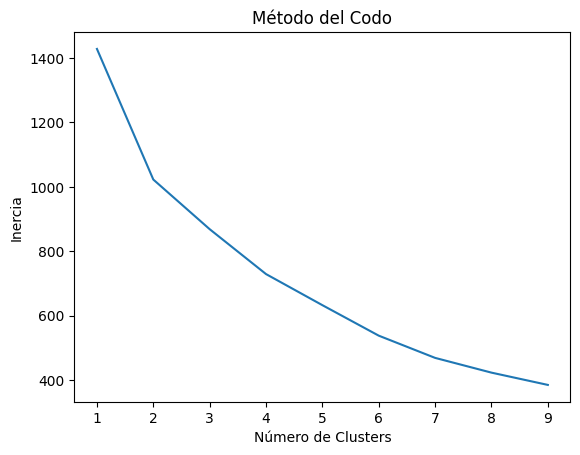

In [23]:
# Normalización de los datos 
df_esg_num_scaled = scaler.fit_transform(df_esg_num)

# Determinar el número óptimo de clusters usando el método del codo
inertias = []
for i in range(1, 10):
    kmeans = KMeans(n_clusters=i, random_state=2024)
    kmeans.fit(df_esg_num_scaled)
    inertias.append(kmeans.inertia_)

# Graficar el método del codo
plt.plot(range(1, 10), inertias)
plt.xlabel('Número de Clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')
plt.show()

In [24]:
print(df_esg_num_scaled)

[[-5.96089227e-01 -7.24439761e-01 -1.45302777e-01  1.09150107e+00
  -7.99119334e-01  3.44820330e-03]
 [-5.58622535e-01 -4.71411722e-01 -5.92555681e-01 -8.80128837e-01
  -5.84938559e-01 -6.01927228e-01]
 [-3.86280093e-01 -9.74974937e-01 -6.73717372e-01  1.54089944e+00
  -4.22001730e-01 -6.01927228e-01]
 ...
 [-7.36707374e-01  5.15347519e-01 -3.03569240e-02 -7.17062710e-01
  -2.49704817e-01 -6.01927228e-01]
 [-6.20882484e-01  5.15347519e-01 -3.03569240e-02 -7.17062710e-01
  -2.49704817e-01 -6.01927228e-01]
 [ 3.94327558e-01  4.28715324e+00 -1.82005372e-01 -6.45027203e-01
   1.56511798e-01  1.12174461e+00]]


## Interpretación: 
Se entrena el algoritmo K-Means para diferentes números de clusters, de 1 a 9. Para cada número de clusters, se calcula la inercia, que mide la suma de las distancias al cuadrado entre cada punto y su centroide más cercano.
El método del codo ayuda a determinar el número óptimo de clusters, según lo observado hay una ligera caída a partir del segundo cluster, por este motivo se escogio trabajar con este valor.

In [25]:
# Ajustar el modelo KMeans con el número óptimo de clusters 
n_clusters = 2 #Según la interpretación del gráfico de codo
kmeans = KMeans(n_clusters=n_clusters, random_state=2024)
kmeans.fit(df_esg_num_scaled)
predicted_cluster_indexes = kmeans.predict(df_esg_num_scaled)

In [26]:
# Agregar los índices de cluster al DataFrame original
df_esg_num['Cluster'] = predicted_cluster_indexes

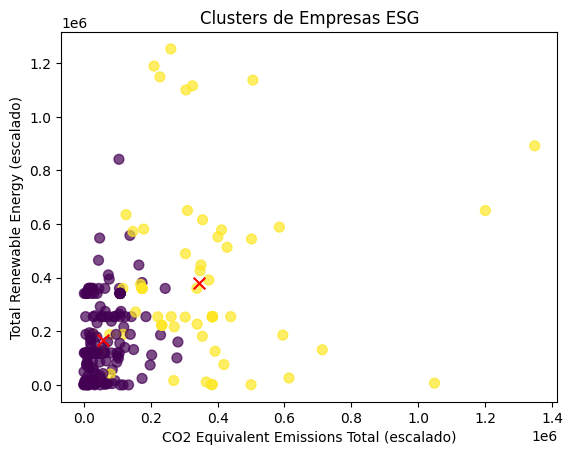

In [27]:
# Graficar los clusters usando .iloc para indexar columnas
plt.scatter(df_esg_num.iloc[:, 0], df_esg_num.iloc[:, 1], 
            c=predicted_cluster_indexes, s=50, alpha=0.7, cmap='viridis')
centers = kmeans.cluster_centers_

centers_scaled = scaler.inverse_transform(centers)  # Invertir la escala para mostrar en el gráfico original

plt.scatter(centers_scaled[:, 0], centers_scaled[:, 1], c='red', s=70, marker='x')  # Centrales
plt.xlabel('CO2 Equivalent Emissions Total (escalado)')
plt.ylabel('Total Renewable Energy (escalado)')
plt.title('Clusters de Empresas ESG')
plt.show()

## Interpretación de los grupos

Cada punto representa una empresa y el color indica el grupo asignado. La posición aproxima el uso de agua y energía; los centroides resumen los dos grupos. Aunque los ejes del gráfico dicen «escalado», el código dibuja estas dos variables en sus unidades originales. Una menor cantidad absoluta de recursos puede reflejar diferencias de tamaño o sector y no basta, por sí sola, para calificar a una empresa como «verde».


### PRUEBA MEDIAS DE LOS CLUSTERS

In [28]:
df_esg_cluster = df_esg_num.copy()
df_esg_cluster['Cluster'] = kmeans.predict(df_esg_num_scaled)
df_esg_cluster.head()

,CO2 Equivalent Emissions Total,Total Renewable Energy,Water Withdrawal Total,Waste Total,Energy Use Total,Donations Total,Cluster
Instrument,,,,,,,
CHRW.OQ,27722.0,62514.0,1245399.89,47220.0,302112.0,4038946,0
AJG.N,34625.0,119407.32,229100.0,1455.996105,600397.2,0,0
FOX.OQ,66378.0,6181.2,44675.0,57651.1,827316.0,0,0
HBAN.OQ,72240.0,4392.0,490066.749,1455.996105,754434.0,15294350,0
QRVO.OQ,281550.0,160169.46,2439000.0,4590.277,1456095.6,0,0


In [29]:
results = pd.DataFrame(columns = ['Cluster', 'Media CO2', 'Media Renewable Energy', 'Media Water Withdrawal', 
                                  'Media Waste', 'Media Energy Use', 'Media Donations'])

for i in range(len(kmeans.cluster_centers_)):
    CO2 = df_esg_cluster[df_esg_cluster['Cluster'] == i]['CO2 Equivalent Emissions Total'].mean()
    reneable = df_esg_cluster[df_esg_cluster['Cluster'] == i]['Total Renewable Energy'].mean()
    water = df_esg_cluster[df_esg_cluster['Cluster'] == i]['Water Withdrawal Total'].mean()
    waste = df_esg_cluster[df_esg_cluster['Cluster'] == i]['Waste Total'].mean()
    energy_use = df_esg_cluster[df_esg_cluster['Cluster'] == i]['Energy Use Total'].mean()
    donations = df_esg_cluster[df_esg_cluster['Cluster'] == i]['Donations Total'].mean()
    
    results.loc[i] = ([i, CO2, reneable, water, waste, energy_use, donations])

results.head(5)

,Cluster,Media CO2,Media Renewable Energy,Media Water Withdrawal,Media Waste,Media Energy Use,Media Donations
0,0.0,58425.603227,166355.567277,8.287732e+05,15002.806942,7.868409e+05,3.832558e+06
1,1.0,343744.509242,379288.447283,3.521781e+06,39820.017980,3.052126e+06,4.493847e+06


In [30]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import itertools

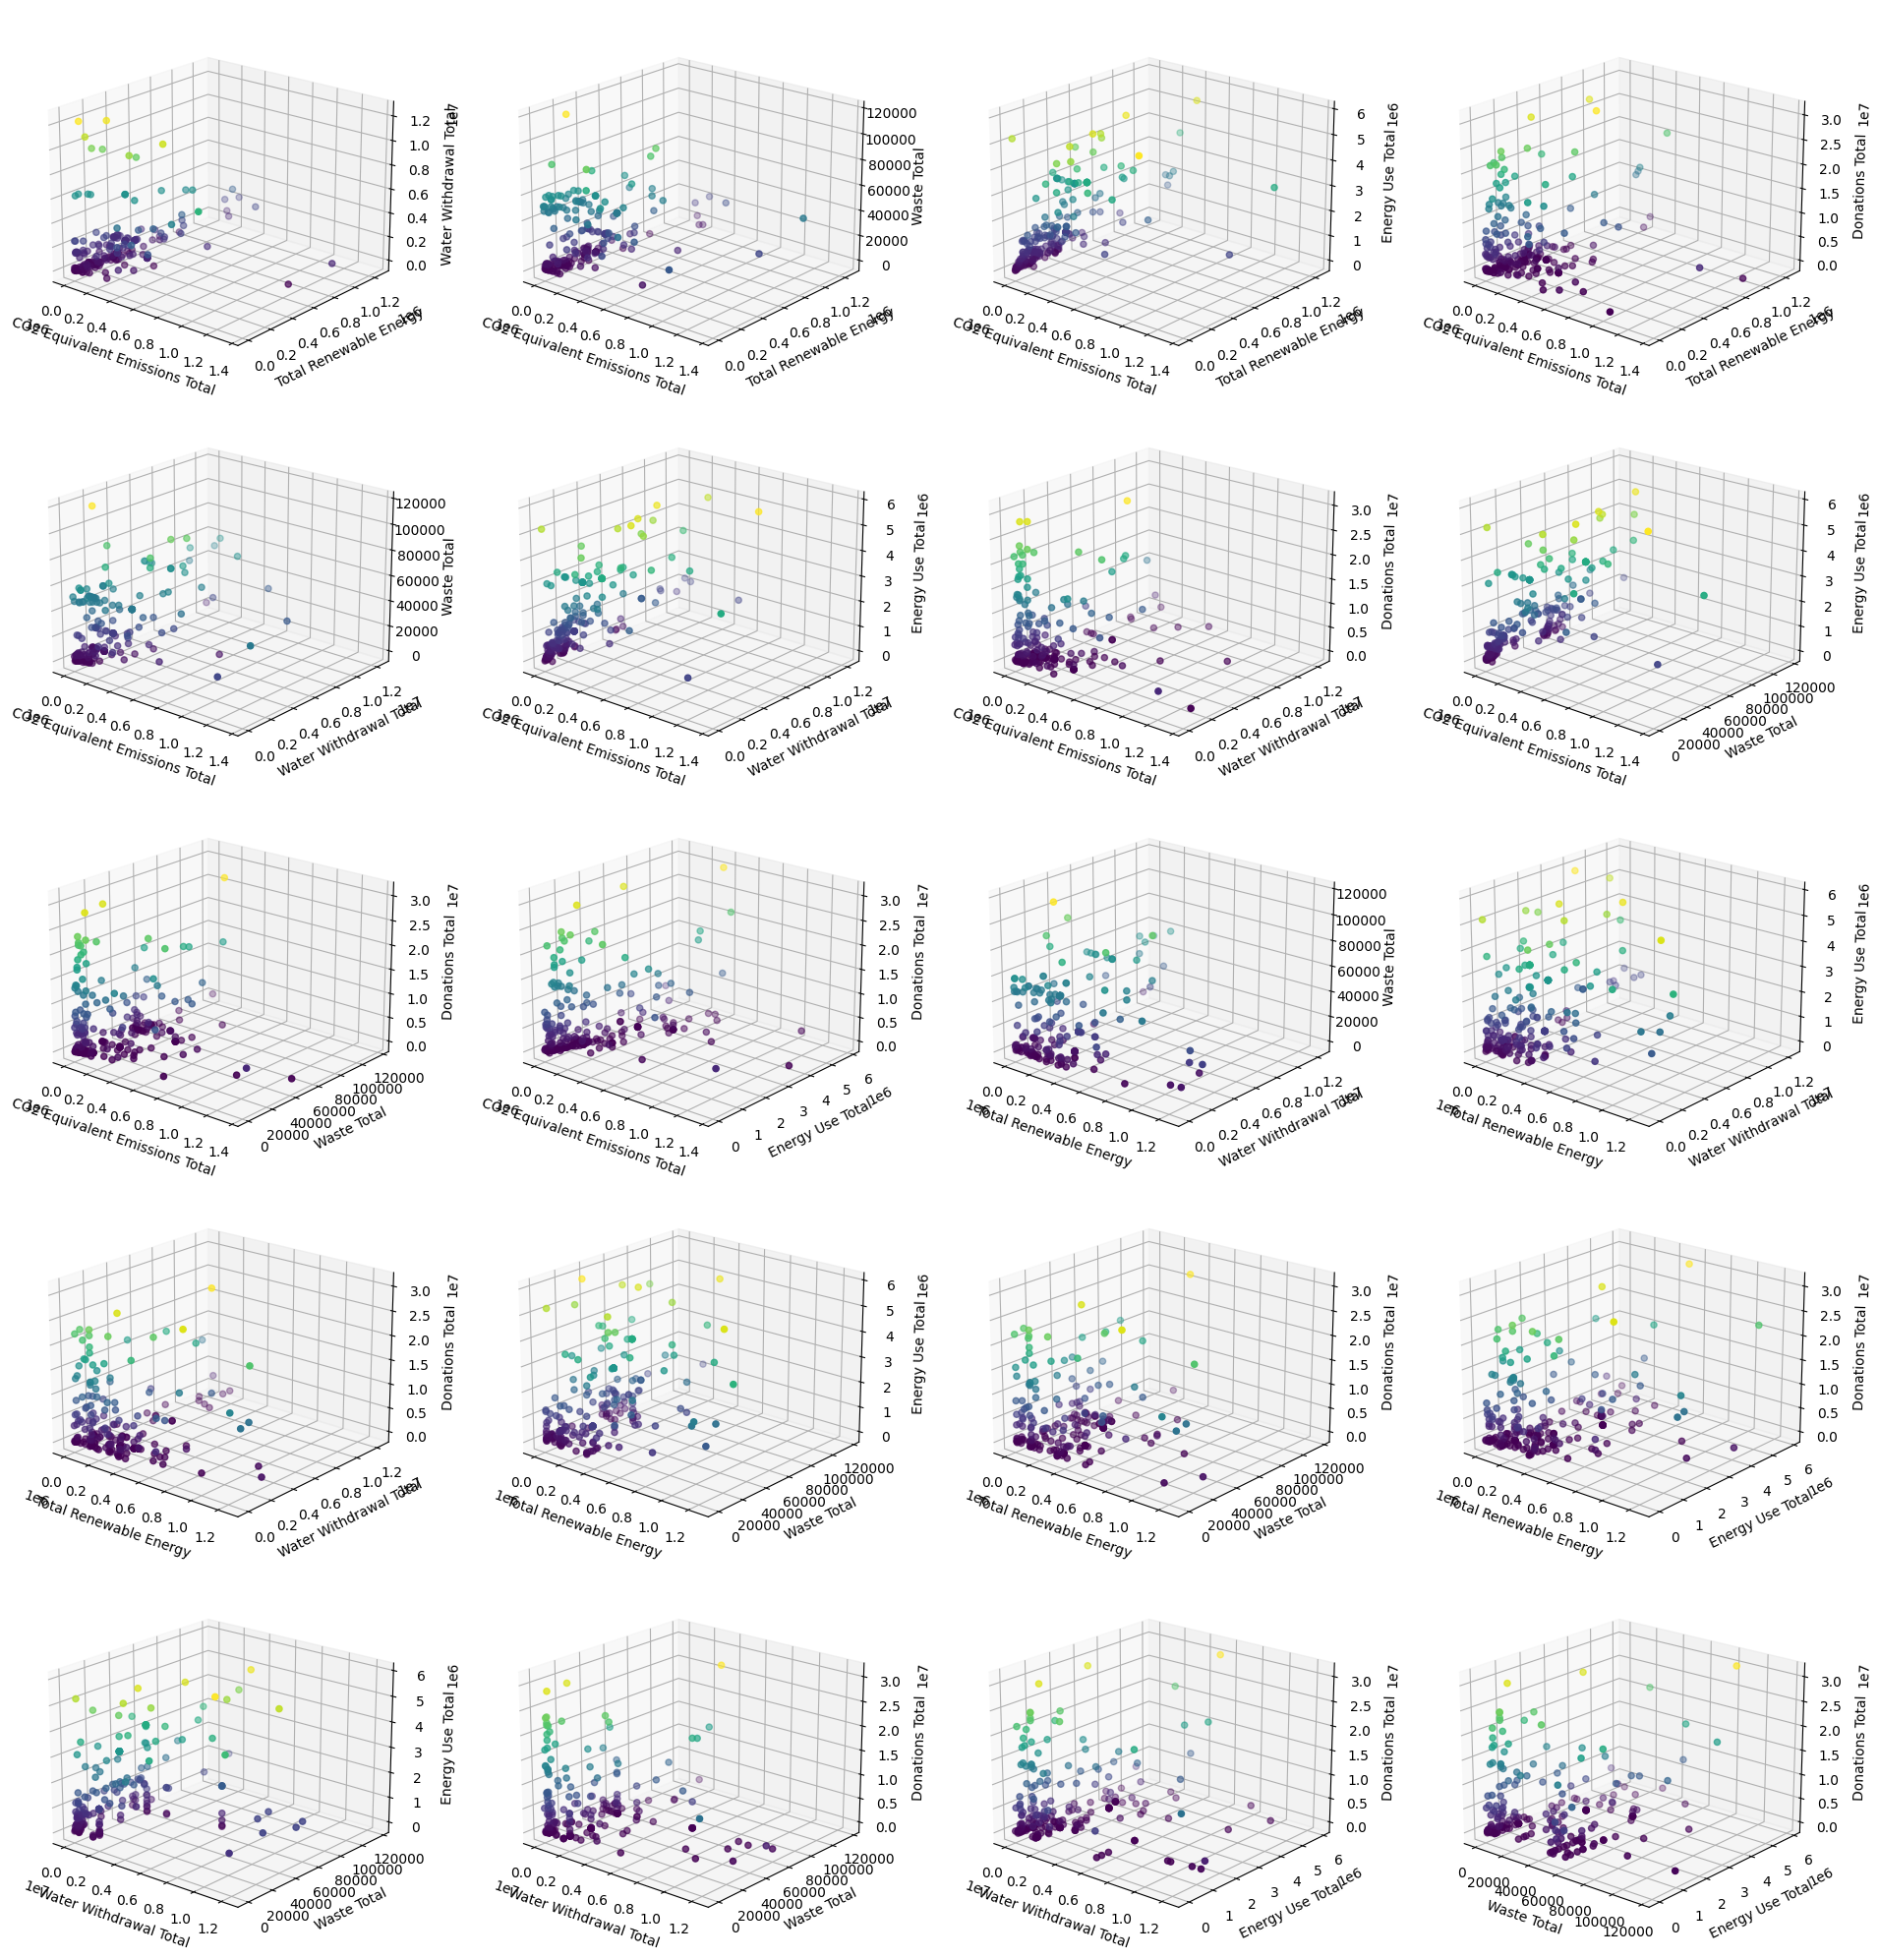

In [31]:
# Asumiendo que Tdisp es el DataFrame con la data
Tdisp = df_esg_cluster

# Definir las variables a combinar
variables = ["CO2 Equivalent Emissions Total", "Total Renewable Energy", "Water Withdrawal Total", 
             "Waste Total", "Energy Use Total", "Donations Total"]

# Generar todas las combinaciones de tres variables para los ejes X, Y y Z
combinations = list(itertools.combinations(variables, 3))

# Configuración de la figura para múltiples subplots
fig = plt.figure(figsize=(20, 20))

# Iterar sobre cada combinación de variables
for i, (x_var, y_var, z_var) in enumerate(combinations, 1):
    ax = fig.add_subplot(5, 4, i, projection='3d')
    
    # Extraer los datos para cada eje
    xdata = Tdisp[x_var]
    ydata = Tdisp[y_var]
    zdata = Tdisp[z_var]
    
    # Configuración del gráfico de dispersión 3D
    scatter = ax.scatter3D(xdata, ydata, zdata, c=zdata, cmap='viridis')
    
    # Etiquetas de los ejes
    ax.set_xlabel(x_var)
    ax.set_ylabel(y_var)
    ax.set_zlabel(z_var)
    
    # Ajuste de la vista (opcional)
    ax.view_init(20, -50)

# Ajuste de espacios entre subplots
plt.tight_layout()
plt.show()

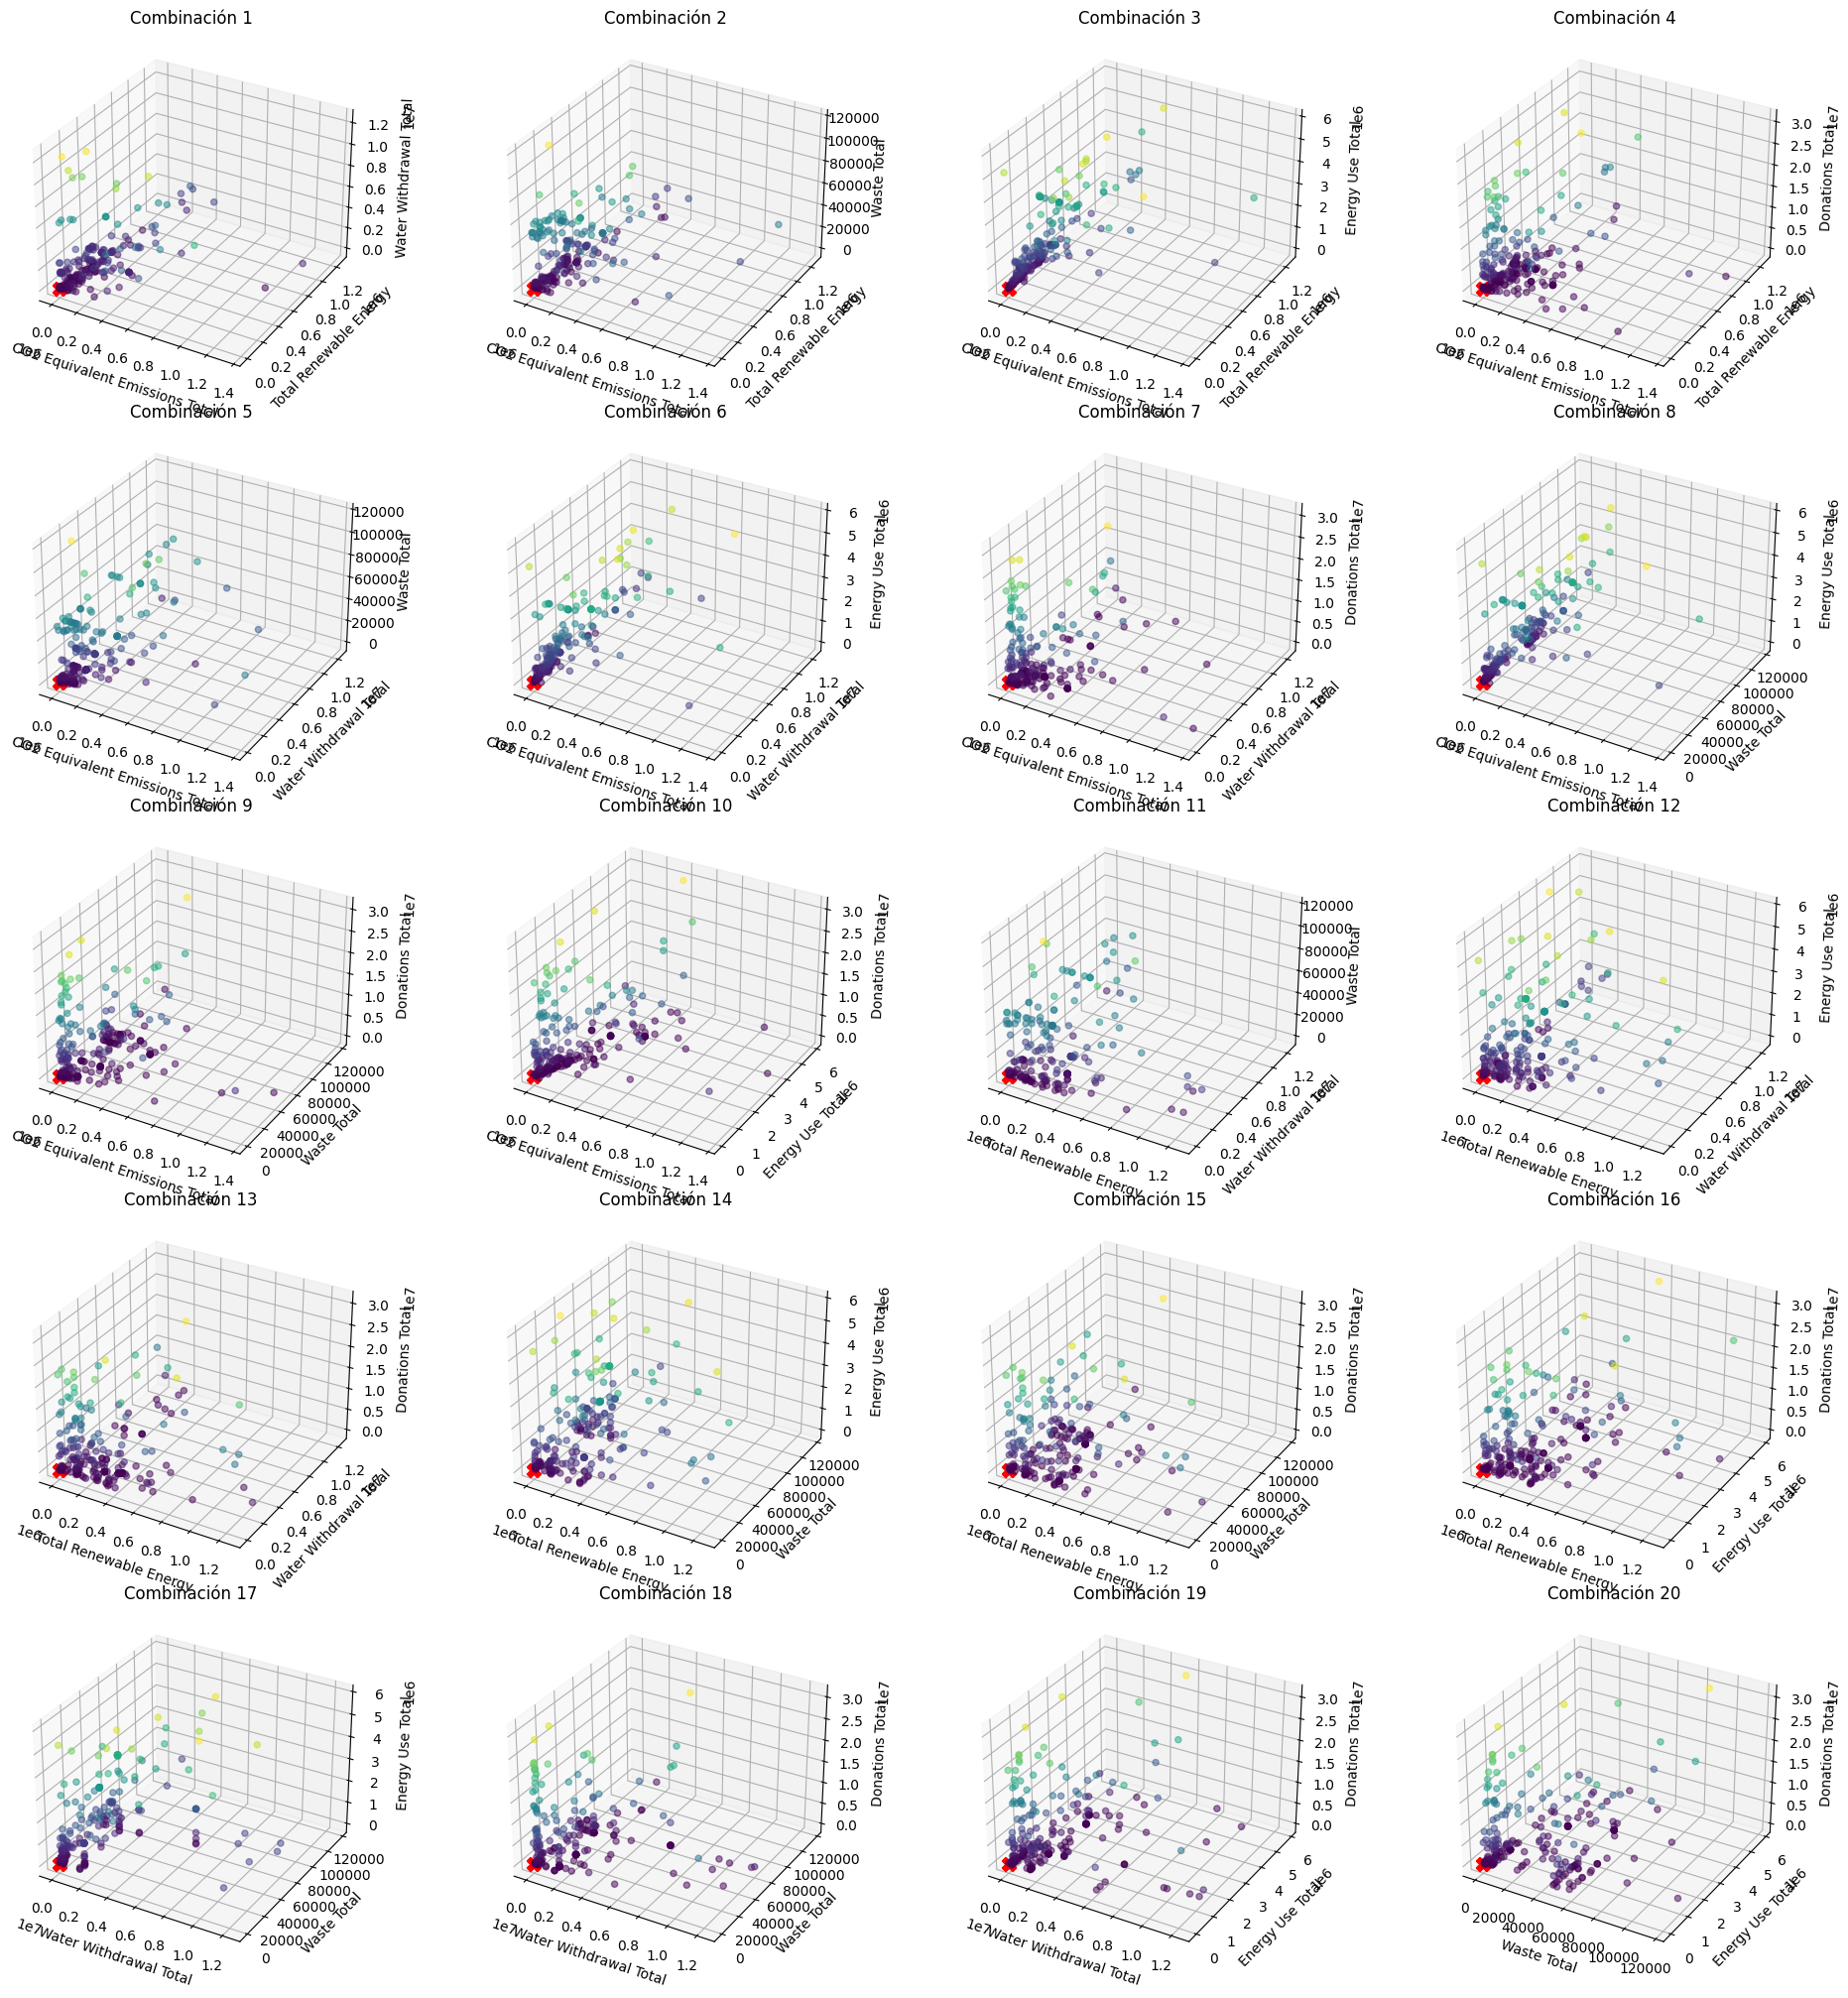

In [32]:
# Asumiendo que Tdisp es el DataFrame con la data y kmeans está ajustado
Tdisp = df_esg_cluster

# Definir las variables a combinar
variables = ["CO2 Equivalent Emissions Total", "Total Renewable Energy", "Water Withdrawal Total", 
             "Waste Total", "Energy Use Total", "Donations Total"]

# Generar todas las combinaciones de tres variables para los ejes X, Y y Z
combinations = list(itertools.combinations(variables, 3))

# Configuración de la figura para múltiples subplots
fig = plt.figure(figsize=(20, 20))

# Iterar sobre cada combinación de variables
for i, (x_var, y_var, z_var) in enumerate(combinations, 1):
    ax = fig.add_subplot(5, 4, i, projection='3d')
    
    # Extraer los datos para cada eje
    xdata = Tdisp[x_var]
    ydata = Tdisp[y_var]
    zdata = Tdisp[z_var]
    
    # Configuración del gráfico de dispersión 3D
    scatter = ax.scatter3D(xdata, ydata, zdata, c=zdata, cmap='viridis', alpha=0.5)
    
    # Graficar los centroides
    # Extraer los índices de las variables para localizar los centroides en el orden adecuado
    x_idx = variables.index(x_var)
    y_idx = variables.index(y_var)
    z_idx = variables.index(z_var)
    
    for centroid in kmeans.cluster_centers_:
        ax.scatter(centroid[x_idx], centroid[y_idx], centroid[z_idx], color='red', s=100, marker='X')

    # Etiquetas de los ejes
    ax.set_xlabel(x_var)
    ax.set_ylabel(y_var)
    ax.set_zlabel(z_var)
    
    # Título para cada gráfico usando la numeración
    ax.set_title(f"Combinación {i}", fontsize=12)

# Ajuste de espacios entre subplots
plt.tight_layout()
plt.show()

# SELECCION DE EMPRESAS

In [33]:
from sklearn.metrics import pairwise_distances
# Encontrar las 25 empresas más cercanas a cada centroide
distances = pairwise_distances(df_esg_num_scaled, kmeans.cluster_centers_)
closest_indices = np.argsort(distances, axis=0)[:25]
print("Nombres de las 50 empresas más cercanas a cada centroide:")
for i in range(n_clusters):
    print(f"\nCentroide {i}:")
    for index in closest_indices[:, i]:
        empresa_nombre = df_esg_num.index[index]  # Aquí obtienes el nombre de la empresa usando el índice
        print(f"Empresa: {empresa_nombre}")



Nombres de las 50 empresas más cercanas a cada centroide:

Centroide 0:
Empresa: GDDY.N
Empresa: NTAP.OQ
Empresa: A.N
Empresa: GPN.N
Empresa: PGR.N
Empresa: PNR.N
Empresa: GL.N
Empresa: CDNS.OQ
Empresa: WAT.N
Empresa: CFG.N
Empresa: WST.N
Empresa: PANW.OQ
Empresa: IR.N
Empresa: TROW.OQ
Empresa: MTD.N
Empresa: CB.N
Empresa: ICE.N
Empresa: MSCI.N
Empresa: BRO.N
Empresa: CPAY.N
Empresa: BRKb.N
Empresa: ERIE.OQ
Empresa: RJF.N
Empresa: WTW.OQ
Empresa: AJG.N

Centroide 1:
Empresa: ZTS.N
Empresa: COR.N
Empresa: APH.N
Empresa: ROL.N
Empresa: VLTO.N
Empresa: LDOS.N
Empresa: ADP.OQ
Empresa: AMTM.N
Empresa: GEV.N
Empresa: AXON.OQ
Empresa: GEHC.OQ
Empresa: PCAR.OQ
Empresa: VRTX.OQ
Empresa: UHS.N
Empresa: ALGN.OQ
Empresa: SOLV.N
Empresa: RVTY.N
Empresa: STE.N
Empresa: LHX.N
Empresa: TT.N
Empresa: ZBH.N
Empresa: CRL.N
Empresa: SYK.N
Empresa: AOS.N
Empresa: LVS.N


# ARMADO DEL PORTAFOLIO CON INVERSIÓN EN ECONOMIAS VERDES

Se decidió trabajar con las 25 empresas más cercanas a cada clúster, lo que da un total de 50 empresas. Aunque las empresas más cercanas al primer cluster o al centroide 0, es decir, las de color lila, podrían estar optimizando el uso de recursos a través de prácticas más sostenibles o porque operan en sectores menos intensivos en consumo de recursos, también es importante considerar que las empresas con puntos amarillos cercanas al otro centroide 1 o pertenecientes al segundo cluster, ya que aportan información valiosa. A pesar de presentar un mayor uso de recursos en comparación con las empresas de puntos lila, representan sectores diferentes que son relevantes para diversificar un portafolio de acciones.

In [34]:
#Importación de las librerias
import math
from scipy.optimize import minimize

# API para acceder a Eikon de los ejemplos del codebook
import os
key = os.environ["EIKON_APP_KEY"]
import eikon as ek
ek.set_app_key(key)


Extracción de los precios de cierre en periodo mensual desde el año 2020 al 2024

In [35]:
#Se omite la empresa GEV.N, AMTM.N y SOLV.N porque no hay datos disponibles para este ticker, en los períodos de tiempo

rics = ['GDDY.N', 'NTAP.OQ', 'GPN.N', 'A.N', 'PGR.N', 'GL.N', 'CDNS.OQ', 'CFG.N', 'PANW.OQ', 
        'PNR.N', 'WAT.N', 'TROW.OQ', 'WST.N', 'IR.N', 'CB.N', 'ICE.N', 'MTD.N', 'BRKb.N', 
        'ERIE.OQ', 'BRO.N', 'MSCI.N', 'CPAY.N', 'RJF.N', 'WTW.OQ','AJG.N','COR.N', 'ZTS.N', 
        'APH.N', 'ROL.N', 'ADP.OQ', 'LDOS.N', 'AXON.OQ', 'VLTO.N',
        'PCAR.OQ', 'GEHC.OQ', 'RVTY.N', 'STE.N', 'UHS.N', 'ALGN.OQ', 'VRTX.OQ',
        'LHX.N', 'ZBH.N', 'AOS.N', 'SYK.N', 'CRL.N', 'TT.N','ARE.N']

data = ek.get_timeseries(rics,
                         fields = 'CLOSE',
                         start_date= '2020-01-01',
                         end_date= '2024-01-01',
                         interval='monthly')

data.head(15)


CLOSE,GDDY.N,NTAP.OQ,GPN.N,A.N,PGR.N,GL.N,CDNS.OQ,CFG.N,PANW.OQ,PNR.N,...,UHS.N,ALGN.OQ,VRTX.OQ,LHX.N,ZBH.N,AOS.N,SYK.N,CRL.N,TT.N,ARE.N
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-31,67.21,53.4,195.45,82.56,80.69,104.26,72.11,37.28,78.259922,42.93,...,137.11,257.1,227.05,221.33,143.481192,42.69,210.7,154.58,103.356636,163.2
2020-02-29,69.98,46.72,183.97,77.07,73.16,92.66,66.14,31.69,61.539938,39.39,...,123.74,218.35,224.03,197.73,132.082246,39.55,190.59,155.57,100.106135,151.88
2020-03-31,57.11,41.69,144.23,71.62,73.84,71.97,66.04,18.81,54.653279,29.76,...,99.08,173.95,237.95,180.12,98.060033,37.81,166.49,126.21,82.59,137.06
2020-04-30,69.43,43.77,166.02,76.66,77.3,82.34,81.13,22.39,65.503268,34.59,...,105.69,214.85,251.2,193.7,116.123723,42.38,186.43,144.67,87.42,157.09
2020-05-31,77.25,44.54,179.49,88.14,77.68,77.02,91.29,24.1,78.423255,39.14,...,105.45,245.62,287.96,199.45,122.56534,47.5,195.73,179.66,90.21,153.72
2020-06-30,73.33,44.37,169.62,88.37,80.11,74.23,95.96,25.24,76.55659,37.99,...,92.89,274.44,290.31,169.67,115.793881,47.12,180.19,174.35,88.98,162.25
2020-07-31,70.28,44.3,178.02,96.33,90.34,79.6,109.25,24.81,85.306581,42.85,...,109.9,293.82,272.0,168.33,130.830788,48.14,193.3,198.99,111.87,177.55
2020-08-31,83.68,47.39,176.62,100.42,95.04,82.48,110.91,25.87,85.803248,45.14,...,110.35,296.98,279.12,180.74,136.670928,48.97,198.16,218.95,118.39,168.38
2020-09-30,75.97,43.84,177.58,100.94,94.67,79.9,106.63,25.28,81.583252,45.77,...,107.02,327.36,272.12,169.84,132.072545,52.8,208.37,226.45,121.25,160.0


In [36]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48 entries, 2020-01-31 to 2023-12-31
Freq: M
Data columns (total 47 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   GDDY.N   48 non-null     Float64
 1   NTAP.OQ  48 non-null     Float64
 2   GPN.N    48 non-null     Float64
 3   A.N      48 non-null     Float64
 4   PGR.N    48 non-null     Float64
 5   GL.N     48 non-null     Float64
 6   CDNS.OQ  48 non-null     Float64
 7   CFG.N    48 non-null     Float64
 8   PANW.OQ  48 non-null     Float64
 9   PNR.N    48 non-null     Float64
 10  WAT.N    48 non-null     Float64
 11  TROW.OQ  48 non-null     Float64
 12  WST.N    48 non-null     Float64
 13  IR.N     48 non-null     Float64
 14  CB.N     48 non-null     Float64
 15  ICE.N    48 non-null     Float64
 16  MTD.N    48 non-null     Float64
 17  BRKb.N   48 non-null     Float64
 18  ERIE.OQ  48 non-null     Float64
 19  BRO.N    48 non-null     Float64
 20  MSCI.N   48 non-null     Flo

In [37]:
#ELIMINAR LAS EMPRESAS   VLTO.N, GEHC.OQ por falta de datos

data = data.drop(columns=['GEHC.OQ','VLTO.N'])

In [38]:
#ELIMINAR LOS NA de los datos
data.dropna(inplace=True)

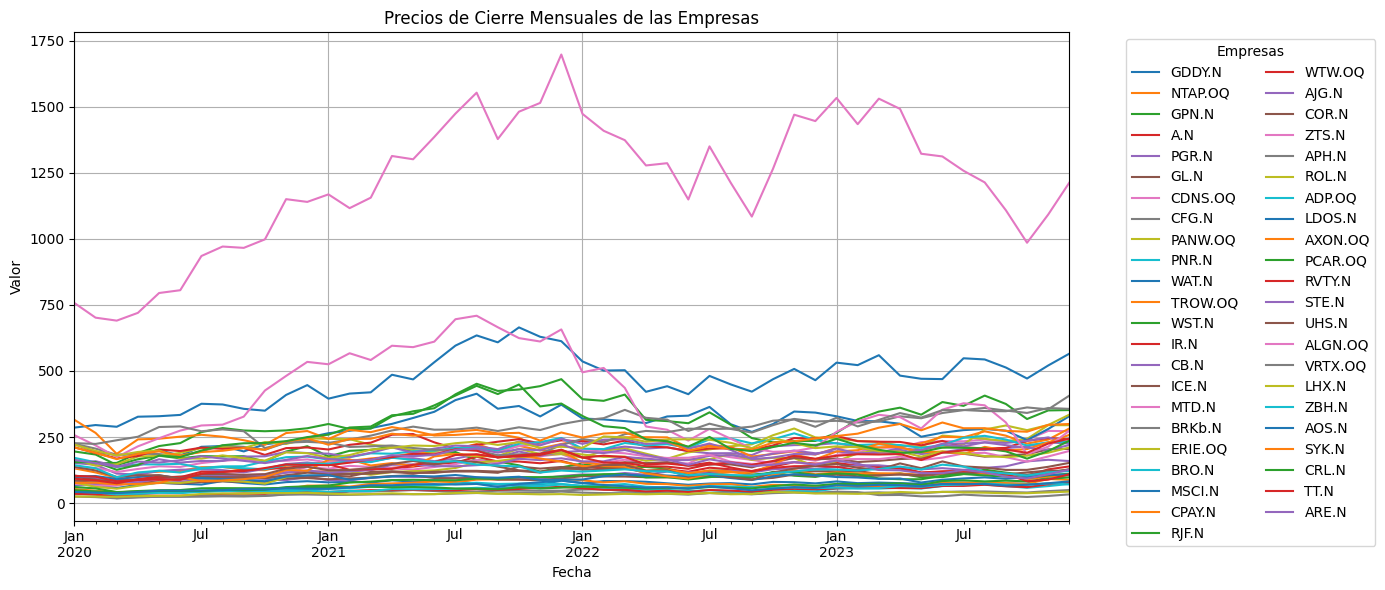

In [39]:
#Grafico para visualizar los precios de las empresas que conforman el portafolio

# Crear un gráfico de líneas para todas las columnas
data.plot(kind='line', figsize=(14, 6))

# Añadir título y etiquetas a los ejes
plt.title('Precios de Cierre Mensuales de las Empresas')
plt.xlabel('Fecha')  # Asegúrate de tener las fechas como índice
plt.ylabel('Valor')

# Ajustar la leyenda para que aparezca fuera del gráfico
plt.legend(title='Empresas', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)  # Cambia el número de columnas si es necesario

# Añadir la cuadrícula y ajustar el diseño
plt.grid(True)
plt.tight_layout()

# Mostrar el gráfico
plt.show()


CÁLCULO DE LOS RETORNOS DE LAS ACCIONES

In [40]:
#Calculo de retonos mensuales Logarítmicos
log_returns = np.log(data/data.shift(1))

#Eliminiar los valores NA
log_returns = log_returns.dropna()

MATRIZ DE COVARIANZAS

In [41]:
#Calculo de la matriz de covarianzas usitlizando  los retornos logarítmicos ANUALIZADOS
cov_matrix = log_returns.cov()*12 
print(cov_matrix.shape)  

(45, 45)


CALCULOS DEL PORTAFOLIO

In [42]:
#Calculo de la desviacion estandar del portafolio
def standard_deviation(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)


In [43]:
#Calculo del retornos esperado del Portafolio

def expected_return(weights, log_returns):
    return np.sum(log_returns.mean()*weights)*12 #Anualizado (12 meses)


CALCULO DE LA TASA LIBRE DE RIESGO

In [44]:
#Calculo de la tasa libre de riesgo con los datos del precio de los bonos 10 year Bond Yield de USA
#Calculo del precio de cierre mensuales de los bonos

rics_rf = ['US10YT=RR']

data_rf = ek.get_timeseries(rics_rf,
                            fields = 'CLOSE',
                            start_date= '2020-01-01',
                            end_date= '2024-01-01', 
                            interval = 'monthly')

data_rf.head(10)

US10YT=RR,CLOSE
Date,
2020-01-31,1.519
2020-02-29,1.126
2020-03-31,0.699
2020-04-30,0.625
2020-05-31,0.644
2020-06-30,0.653
2020-07-31,0.536
2020-08-31,0.693
2020-09-30,0.677


In [45]:
# Calcular el logaritmo natural de la relación (precio final/precio inicial)
data_rf['ln_ratio'] = np.log(data_rf['CLOSE'] / data_rf['CLOSE'].shift(1))

# Eliminar posibles valores nulos o NA
data_rf.dropna(inplace=True)

# Calcular el promedio de la nueva columna 'ln_ratio'
risk_free_rate = data_rf['ln_ratio'].mean()

print(f'El Rf rate es: {risk_free_rate}')

El Rf rate es: 0.019842871486449015


In [46]:
#Calculo del Ratio de Sharpe

def sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return (expected_return(weights, log_returns) - risk_free_rate) / standard_deviation(weights, cov_matrix)



DEFINIR LA FUNCION PARA MINIMIZAR (Negative Sharpe Ratio)

In [47]:
def neg_sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return -sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate)


RESTRICCIONES EN EL LOS PESOS DEL PORTAFOLIO

## Restricciones: 
- El límite inferior de cero indica que no hay pesos negativos; por lo tanto, NO PODEMOS ir en SHORT en ninguna acción.
- El límite superior de 0.5 significa que no podemos invertir más del 50% de nuestro portafolio en ninguna acción.


In [48]:
constraints = {'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1}
bounds = [(0, 0.5) for _ in range(len(log_returns.columns))]

In [49]:
#Definir los pesos iniciales
initial_weights = np.array([1/len(log_returns.columns)]*len(log_returns.columns))

OPTIMIZAR LOS PESOS PARA MAXIMIZAR EL RATIO DE SHARPE

In [50]:
from scipy.optimize import minimize
optimized_results = minimize(neg_sharpe_ratio, initial_weights, args=(log_returns, cov_matrix, risk_free_rate),
                             method='SLSQP', constraints=constraints,bounds=bounds)

RESULTADOS DE LOS PESOS ÓPTIMOS

In [51]:
optimal_weights = optimized_results.x

ANÁLISIS DEL PORTAFOLIO ÓPTIMO

In [52]:
#Datos de los pesos óptimos correspondiente a cada ticker
print("Optimal Weights:")
for ticker, weight in zip(data, optimal_weights):
    print(f"{ticker}: {weight:.4f}")

optimal_portfolio_return = expected_return(optimal_weights, log_returns)
optimal_portfolio_volatility = standard_deviation(optimal_weights, cov_matrix)
optimal_sharpe_ratio = sharpe_ratio(optimal_weights, log_returns, cov_matrix, risk_free_rate)

print(f"Retornos Anuales Esperados del Portafolio: {optimal_portfolio_return:.4f}")
print(f"Riesgo Esperado del Portafolio: {optimal_portfolio_volatility:.4f}")
print(f"Ratio de Sharpe: {optimal_sharpe_ratio:.4f}")

Optimal Weights:
GDDY.N: 0.0000
NTAP.OQ: 0.0000
GPN.N: 0.0000
A.N: 0.0000
PGR.N: 0.1665
GL.N: 0.0000
CDNS.OQ: 0.2758
CFG.N: 0.0000
PANW.OQ: 0.0312
PNR.N: 0.0000
WAT.N: 0.0000
TROW.OQ: 0.0000
WST.N: 0.0000
IR.N: 0.0000
CB.N: 0.0000
ICE.N: 0.0000
MTD.N: 0.0000
BRKb.N: 0.0000
ERIE.OQ: 0.0402
BRO.N: 0.0000
MSCI.N: 0.0000
CPAY.N: 0.0000
RJF.N: 0.0000
WTW.OQ: 0.0000
AJG.N: 0.0000
COR.N: 0.3927
ZTS.N: 0.0000
APH.N: 0.0000
ROL.N: 0.0000
ADP.OQ: 0.0000
LDOS.N: 0.0000
AXON.OQ: 0.0751
PCAR.OQ: 0.0000
RVTY.N: 0.0000
STE.N: 0.0000
UHS.N: 0.0000
ALGN.OQ: 0.0000
VRTX.OQ: 0.0184
LHX.N: 0.0000
ZBH.N: 0.0000
AOS.N: 0.0000
SYK.N: 0.0000
CRL.N: 0.0000
TT.N: 0.0000
ARE.N: 0.0000
Retornos Anuales Esperados del Portafolio: 0.2541
Riesgo Esperado del Portafolio: 0.1588
Ratio de Sharpe: 1.4756


## Interpretación del ratio de Sharpe

La salida muestra un valor calculado de 1,4756 para la cartera ajustada con estos datos. La tasa usada como libre de riesgo procede del cambio logarítmico de una serie de rendimiento del bono a diez años, no del nivel de una tasa libre de riesgo comparable. Por ello, este ratio no permite concluir que el rendimiento ajustado al riesgo esté validado.


GRÁFICOS DE LOS PESOS ÓPTIMOS DEL PORTAFOLIO

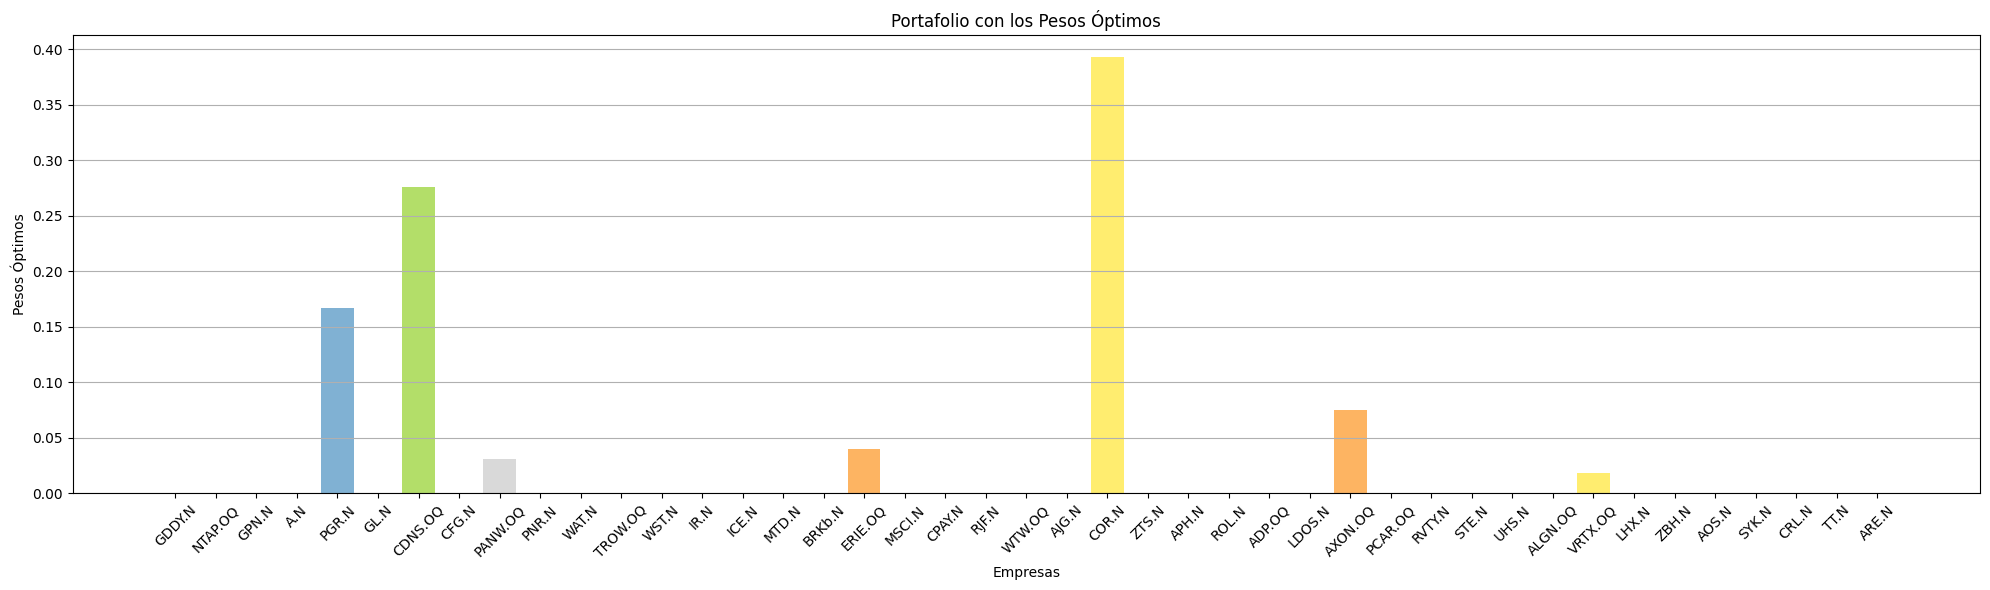

In [56]:
#Gráfico de barras
# Filtrar los tickers y pesos óptimos donde los pesos son mayores a 0
positive_weights = [(ticker, weight) for ticker, weight in zip(data, optimal_weights) if weight > 0]
tickers, weights = zip(*positive_weights) 

# Paleta de colores pastel
pastel_colors = sns.color_palette("pastel", len(tickers))

# Graficar
plt.figure(figsize=(20, 6))
plt.bar(tickers, weights, color=plt.cm.Set3.colors)  
plt.xlabel('Empresas')
plt.ylabel('Pesos Óptimos')
plt.title('Portafolio con los Pesos Óptimos')
plt.xticks(rotation=45) 
plt.grid(axis='y')  
plt.tight_layout()  
plt.show()


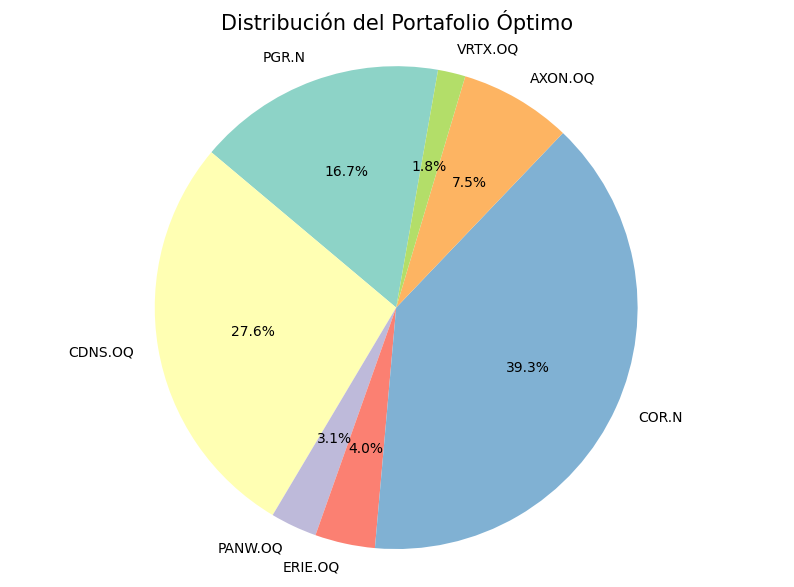

In [57]:
#Gráfico de Torta
# Filtrar los tickers y pesos óptimos donde los pesos son mayores a 0
positive_weights = [(ticker, weight) for ticker, weight in zip(data.columns, optimal_weights) if weight > 0.001]
if positive_weights: 
    tickers, weights = zip(*positive_weights)  

    # Crear un gráfico de torta solo con las empresas que tienen peso mayor a 0
    plt.figure(figsize=(10, 7))  
    plt.pie(weights, labels=tickers, autopct='%1.1f%%', startangle=80, colors=plt.cm.Set3.colors)

    # Añadir título
    plt.title('Distribución del Portafolio Óptimo', fontsize = 15)

    # Asegurarse de que el gráfico se vea como un círculo
    plt.axis('equal')

    # Mostrar gráfico
    plt.show()
else:
    print("No hay empresas con pesos positivos para graficar.")


# Conclusiones del análisis ESG y la primera cartera

Se analizaron variables ESG individuales, se exploraron sus distribuciones por sector y se agruparon las empresas con K-Means. La selección de candidatas incluyó empresas próximas a ambos centroides para examinar perfiles distintos. La cercanía a un centroide resume similitudes dentro de las variables estudiadas; no demuestra sostenibilidad integral.

Con precios de cierre mensuales se calculó una primera cartera bajo restricciones de pesos. Sus salidas históricas muestran un retorno medio anualizado estimado de 25,41 % y una volatilidad anualizada de 15,88 %. Son resultados del ajuste con los datos disponibles, no rendimientos realizados ni una validación prospectiva. El ratio de Sharpe presentado depende de la tasa libre de riesgo calculada como se indicó arriba y debe interpretarse con esa limitación.


# ANALISIS BENCHMARRK

## CALCULO DEL RETORNO Y RIESGO DE LOS INDICES SP500, NASDAQ Y DOW JONES

In [58]:
#Se omite la empresa GEV.N, AMTM.N y SOLV.N porque no hay datos disponibles para este ticker,


rics_indices = ['.SPX','.NDX','.DJI']

data_indices = ek.get_timeseries(rics_indices,
                         fields = 'CLOSE',
                         start_date= '2023-01-01',
                         end_date= '2024-01-01',
                         interval='monthly')

data_indices.head(15)

CLOSE,.SPX,.NDX,.DJI
Date,,,
2023-01-31,4076.6,12101.929,34086.03658
2023-02-28,3970.15,12042.116,32656.69804
2023-03-31,4109.31,13181.351,33274.15357
2023-04-30,4169.48,13245.986,34098.16358
2023-05-31,4179.83,14254.09,32908.26743
2023-06-30,4450.38,15179.208,34407.59985
2023-07-31,4588.96,15756.999,35559.53322
2023-08-31,4507.66,15501.074,34721.91329
2023-09-30,4288.05,14715.244,33507.4995


In [59]:
data_indices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12 entries, 2023-01-31 to 2023-12-31
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   .SPX    12 non-null     Float64
 1   .NDX    12 non-null     Float64
 2   .DJI    12 non-null     Float64
dtypes: Float64(3)
memory usage: 420.0 bytes


In [60]:
#Calculo de retonos mensuales Logarítmicos
log_returns_index = np.log(data_indices/data_indices.shift(1))

In [61]:
# Rendimientos medios mensuales y anuales
mean_monthly_returns = log_returns_index.mean()
mean_annual_returns = mean_monthly_returns * 12


In [62]:
# Desviación estándar (riesgo) mensual 
std_dev_monthly = log_returns_index.std()

In [63]:
# Desviación estándar (riesgo) anual
std_dev_annual = std_dev_monthly * np.sqrt(12)

## CALCULO DEL RISK FREE RATE 

In [64]:
#Calculo de la tasa libre de riesgo con los datos del precio de los bonos 10 year Bond Yield de USA

#Calculo del precio de cierre mensuales de los bonos
rics_rf_index = ['US10YT=RR']

data_rf_index = ek.get_timeseries(rics_rf_index,
                            fields = 'CLOSE',
                            start_date= '2023-01-01',
                            end_date= '2024-01-01', 
                            interval = 'monthly')

data_rf_index.head(10)


US10YT=RR,CLOSE
Date,
2023-01-31,3.529
2023-02-28,3.914
2023-03-31,3.49
2023-04-30,3.452
2023-05-31,3.637
2023-06-30,3.819
2023-07-31,3.957
2023-08-31,4.091
2023-09-30,4.571


In [65]:
# Calcular el logaritmo natural de la relación (precio final/precio inicial)
data_rf_index['ln_ratio'] = np.log(data_rf_index['CLOSE'] / data_rf_index['CLOSE'].shift(1))

# Eliminar posibles valores nulos o NA
data_rf_index.dropna(inplace=True)

# Calcular el promedio de la nueva columna 'ln_ratio'
risk_free_rate_index = data_rf_index['ln_ratio'].mean()

print(f'El Rf rate es: {risk_free_rate_index}')

El Rf rate es: 0.008150239889418777


In [66]:
# Anualizar la tasa libre de riesgo
risk_free_rate_index = (1 + risk_free_rate_index) ** 12 - 1
print(f'El Rf anualizado es: {risk_free_rate_index}')

El Rf anualizado es: 0.10230834073596373


## RESULTADOS DE LOS INDICES ANALIZADOS

In [67]:
# Calcular el Ratio de Sharpe para cada índice
sharpe_ratio = (mean_annual_returns - risk_free_rate_index) / std_dev_annual

# Resultados
print("Rendimientos medios mensuales:\n", mean_monthly_returns)
print("Rendimientos medios anuales:\n", mean_annual_returns)
print("Desviación estándar mensual (riesgo mensual):\n", std_dev_monthly)
print("Desviación estándar anual (riesgo anual):\n", std_dev_annual)
print("Ratio de Sharpe de cada índice:\n", sharpe_ratio)

Rendimientos medios mensuales:
 CLOSE
.SPX    0.014277
.NDX    0.029960
.DJI    0.009136
dtype: float64
Rendimientos medios anuales:
 CLOSE
.SPX    0.171324
.NDX    0.359516
.DJI    0.109631
dtype: float64
Desviación estándar mensual (riesgo mensual):
 CLOSE
.SPX    0.041491
.NDX    0.050645
.DJI    0.041850
dtype: float64
Desviación estándar anual (riesgo anual):
 CLOSE
.SPX    0.143728
.NDX    0.175438
.DJI    0.144971
dtype: float64
Ratio de Sharpe de cada índice:
 CLOSE
.SPX    0.480186
.NDX    1.466086
.DJI    0.050508
dtype: float64


## CALCULO DEL PORTAFOLIO

In [70]:

rics_nuevo = ['GDDY.N', 'NTAP.OQ', 'GPN.N', 'A.N', 'PGR.N', 'GL.N', 'CDNS.OQ', 'CFG.N', 'PANW.OQ', 
              'PNR.N', 'WAT.N', 'TROW.OQ', 'WST.N', 'IR.N', 'CB.N', 'ICE.N', 'MTD.N', 'BRKb.N', 
              'ERIE.OQ', 'BRO.N', 'MSCI.N', 'CPAY.N', 'RJF.N', 'WTW.OQ','AJG.N','COR.N', 'ZTS.N', 
              'APH.N', 'ROL.N', 'ADP.OQ', 'LDOS.N', 'AXON.OQ', 'VLTO.N',
              'PCAR.OQ', 'GEHC.OQ', 'RVTY.N', 'STE.N', 'UHS.N', 'ALGN.OQ', 'VRTX.OQ',
              'LHX.N', 'ZBH.N', 'AOS.N', 'SYK.N', 'CRL.N', 'TT.N','ARE.N']

data_nuevo = ek.get_timeseries(rics_nuevo,
                         fields = 'CLOSE',
                         start_date= '2023-01-01',
                         end_date= '2024-01-01',
                         interval='monthly')

data_nuevo.head(15)

CLOSE,GDDY.N,NTAP.OQ,GPN.N,A.N,PGR.N,GL.N,CDNS.OQ,CFG.N,PANW.OQ,PNR.N,...,UHS.N,ALGN.OQ,VRTX.OQ,LHX.N,ZBH.N,AOS.N,SYK.N,CRL.N,TT.N,ARE.N
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-31,82.13,66.23,112.72,152.08,136.35,120.85,182.83,43.32,158.64,55.38,...,148.21,269.73,323.1,214.82,127.34,67.7,253.81,243.25,179.12,160.74
2023-02-28,75.71,64.55,112.2,141.97,143.52,121.69,192.94,41.76,188.37,55.94,...,133.57,309.5,290.29,211.19,123.87,65.63,262.88,219.34,184.97,149.78
2023-03-31,77.72,63.85,105.24,138.34,143.06,110.02,210.09,30.37,199.74,55.27,...,127.1,334.14,315.07,196.24,129.2,69.15,285.47,201.82,183.98,125.59
2023-04-30,75.68,62.89,112.71,135.43,136.4,108.52,209.45,30.94,182.46,58.08,...,150.35,325.3,340.73,195.15,138.44,68.29,299.65,190.12,185.81,124.18
2023-05-31,73.38,66.35,97.69,115.67,127.91,103.18,230.91,25.78,213.39,55.47,...,132.13,282.66,323.57,175.92,127.34,63.94,275.58,193.38,163.23,113.46
2023-06-30,75.13,76.4,98.52,120.25,132.37,109.62,234.52,26.08,255.51,64.6,...,157.77,353.64,351.91,195.77,145.6,72.78,305.09,210.25,191.26,113.49
2023-07-31,77.09,78.01,110.25,121.77,125.98,112.17,234.01,32.26,249.96,69.5,...,138.96,377.89,352.34,189.49,138.15,72.63,283.41,209.54,199.44,125.68
2023-08-31,72.51,76.7,126.69,121.07,133.47,111.57,240.44,28.13,243.3,70.26,...,134.7,370.14,348.34,178.09,119.12,72.5,283.55,206.82,205.26,116.34
2023-09-30,74.48,75.88,115.39,111.82,139.3,108.73,234.3,26.8,234.44,64.75,...,125.73,305.32,347.74,174.12,112.22,66.13,273.27,195.98,202.91,100.1


In [71]:
#ELIMINAR LAS EMPRESAS   VLTO.N, GEHC.OQ por falta de datos

data_nuevo = data_nuevo.drop(columns=['VLTO.N'])

In [72]:
#ELIMINAR LOS NA de los datos
data_nuevo.dropna(inplace=True)

In [73]:
#Calculo de retonos mensuales Logarítmicos
log_returns_nuevo = np.log(data_nuevo/data_nuevo.shift(1))

#Eliminiar los valores NA
log_returns_nuevo = log_returns_nuevo.dropna()

In [74]:
#Calculo de la matriz de covarianzas usitlizando  los retornos logarítmicos ANUALIZADOS
cov_matrix_nuevo = log_returns_nuevo.cov()*12 
print(cov_matrix_nuevo.shape)  

(46, 46)


In [75]:
#Calculo de la desviacion estandar del portafolio
def standard_deviation(weights_nuevo, cov_matrix_nuevo):
    variance_nuevo = weights_nuevo.T @ cov_matrix_nuevo @ weights_nuevo
    return np.sqrt(variance_nuevo)

In [76]:
#Calculo del retornos esperado del Portafolio

def expected_return(weights_nuevo, log_returns_nuevo):
    return np.sum(log_returns_nuevo.mean()*weights_nuevo)*12 #Anualizado (12 meses)

In [77]:
#Calculo del Ratio de Sharpe

def sharpe_ratio(weights_nuevo, log_returns_nuevo, cov_matrix_nuevo, risk_free_rate_index):
    return (expected_return(weights_nuevo, log_returns_nuevo) - risk_free_rate_index) / standard_deviation(weights_nuevo, cov_matrix_nuevo)



In [78]:
def neg_sharpe_ratio(weights_nuevo, log_returns_nuevo, cov_matrix_nuevo, risk_free_rate_index):
    return -sharpe_ratio(weights_nuevo, log_returns_nuevo, cov_matrix_nuevo, risk_free_rate_index)

In [79]:
constraints_nuevo = {'type': 'eq', 'fun': lambda weights_nuevo: np.sum(weights_nuevo) - 1}
bounds_nuevo = [(0, 0.5) for _ in range(len(log_returns_nuevo.columns))]

In [80]:
#Definir los pesos iniciales
initial_weights_nuevo = np.array([1/len(log_returns_nuevo.columns)]*len(log_returns_nuevo.columns))

In [81]:
from scipy.optimize import minimize
optimized_results_nuevo = minimize(neg_sharpe_ratio, initial_weights_nuevo, args=(log_returns_nuevo, cov_matrix_nuevo, risk_free_rate_index),
                          method='SLSQP', constraints=constraints_nuevo,bounds=bounds_nuevo)

In [83]:
optimal_weights_nuevo = optimized_results_nuevo.x

In [84]:
#Datos de los pesos óptimos correspondiente a cada ticker
print("Optimal Weights:")
for ticker, weight in zip(data_nuevo, optimal_weights_nuevo):
    print(f"{ticker}: {weight:.4f}")

optimal_portfolio_return_nuevo = expected_return(optimal_weights_nuevo, log_returns_nuevo)
optimal_portfolio_volatility_nuevo = standard_deviation(optimal_weights_nuevo, cov_matrix_nuevo)
optimal_sharpe_ratio_nuevo = sharpe_ratio(optimal_weights_nuevo, log_returns_nuevo, cov_matrix_nuevo, risk_free_rate_index)

print(f"Retornos Anuales Esperados del Portafolio: {optimal_portfolio_return_nuevo:.4f}")
print(f"Riesgo Esperado del Portafolio: {optimal_portfolio_volatility_nuevo:.4f}")
print(f"Ratio de Sharpe: {optimal_sharpe_ratio_nuevo:.4f}")

Optimal Weights:
GDDY.N: 0.0000
NTAP.OQ: 0.0000
GPN.N: 0.0000
A.N: 0.0000
PGR.N: 0.0772
GL.N: 0.0000
CDNS.OQ: 0.3867
CFG.N: 0.0000
PANW.OQ: 0.1225
PNR.N: 0.0000
WAT.N: 0.0000
TROW.OQ: 0.0000
WST.N: 0.0000
IR.N: 0.0000
CB.N: 0.0000
ICE.N: 0.0000
MTD.N: 0.0000
BRKb.N: 0.0000
ERIE.OQ: 0.1441
BRO.N: 0.0000
MSCI.N: 0.0000
CPAY.N: 0.0000
RJF.N: 0.0000
WTW.OQ: 0.0000
AJG.N: 0.0000
COR.N: 0.0000
ZTS.N: 0.0000
APH.N: 0.0000
ROL.N: 0.0000
ADP.OQ: 0.0000
LDOS.N: 0.0000
AXON.OQ: 0.0000
PCAR.OQ: 0.0000
GEHC.OQ: 0.0000
RVTY.N: 0.0000
STE.N: 0.0000
UHS.N: 0.0000
ALGN.OQ: 0.0000
VRTX.OQ: 0.2694
LHX.N: 0.0000
ZBH.N: 0.0000
AOS.N: 0.0000
SYK.N: 0.0000
CRL.N: 0.0000
TT.N: 0.0000
ARE.N: 0.0000
Retornos Anuales Esperados del Portafolio: 0.3815
Riesgo Esperado del Portafolio: 0.0983
Ratio de Sharpe: 2.8396


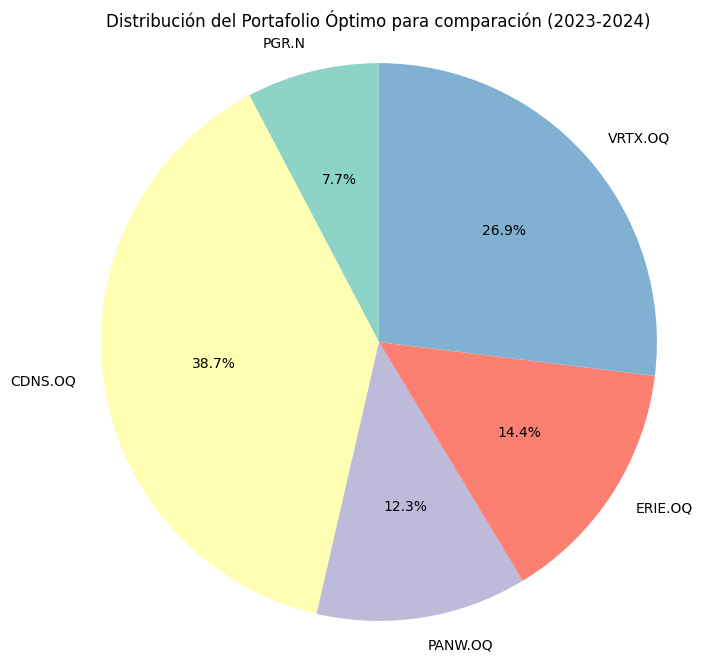

In [87]:
#Gráfico de Torta
# Filtrar los tickers y pesos óptimos donde los pesos son mayores a 0
positive_weights = [(ticker, weight) for ticker, weight in zip(data_nuevo.columns, optimal_weights_nuevo) if weight> 0.0001]
if positive_weights: 
    tickers, weights = zip(*positive_weights)  

    # Crear un gráfico de torta solo con las empresas que tienen peso mayor a 0
    plt.figure(figsize=(8, 8))  
    plt.pie(weights, labels=tickers, autopct='%1.1f%%', startangle=90, colors=plt.cm.Set3.colors)

    # Añadir título
    plt.title('Distribución del Portafolio Óptimo para comparación (2023-2024)')

    # Asegurarse de que el gráfico se vea como un círculo
    plt.axis('equal')

    # Mostrar gráfico
    plt.show()
else:
    print("No hay empresas con pesos positivos para graficar.")

### CONCLUSION

La comparación histórica de enero de 2023 a enero de 2024 muestra 38,15 % de retorno anualizado calculado y 9,83 % de volatilidad anualizada para la cartera reoptimizada, junto a los valores de los tres índices de referencia. La optimización y la comparación utilizaron el mismo periodo, por lo que esas diferencias no son evidencia de que la estrategia superaría a los índices fuera de muestra. El ratio de Sharpe de esta comparación también depende del cálculo de la tasa libre de riesgo señalado anteriormente.

El ejercicio muestra un camino para combinar exploración ESG, agrupación y optimización de pesos. Una evaluación de inversión necesitaría separar los datos usados para construir la cartera de los usados para medir su desempeño y revisar los supuestos de los indicadores ESG y de la tasa libre de riesgo.
